## 1. Introduction

In this notebook, we explore ranking and retrieval on two datasets constructed from publicly available data:

- CAIQ: Security questionnaire rows, where the relevant documents are the answers to the same or related controls.
- FiQA: questions and answers from a personal finance forum.

We measure the ranking quality of the top 10 documents output by a ranking algorithm with nDCG@10, the normalized discounted cumulative gain,

$$\mathrm{DCG@10} = \sum_{i=1}^{10} \frac{2^{g_i} - 1}{\log_2(i + 1)}, \qquad \mathrm{nDCG@10} = \frac{\mathrm{DCG@10}}{\mathrm{IDCG@10}},$$

where $g_i$ is the relevance grade of the document at rank $i$ (0 when it is not relevant) and $\mathrm{IDCG@10}$ is the $\mathrm{DCG@10}$ of the best possible ranking, so a perfect ranking scores 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lab

ENCODE_ON_GPU = False  # late interaction: False uses the downloaded token vectors; True encodes them again on your GPU

caiq, fiqa = lab.load("caiq"), lab.load("fiqa")
DATASETS = (caiq, fiqa)

In [2]:
print(f"{'':6s}{'documents':>11s}{'questions':>11s}{'median words per document':>28s}{'relevant per question':>24s}")
for ds in DATASETS:
    words = [len(lab.tokenize(t)) for t in ds.bodies]
    rel = [sum(g > 0 for g in q.values()) for q in ds.qrels.values()]
    print(f"{lab.NAMES[ds.name]:6s}{len(ds.ids):11,d}{len(ds.queries):11,d}{np.median(words):28.0f}{np.mean(rel):24.1f}")

        documents  questions   median words per document   relevant per question
CAIQ          644        119                          24                     9.7


FiQA       57,912        648                          95                     2.6


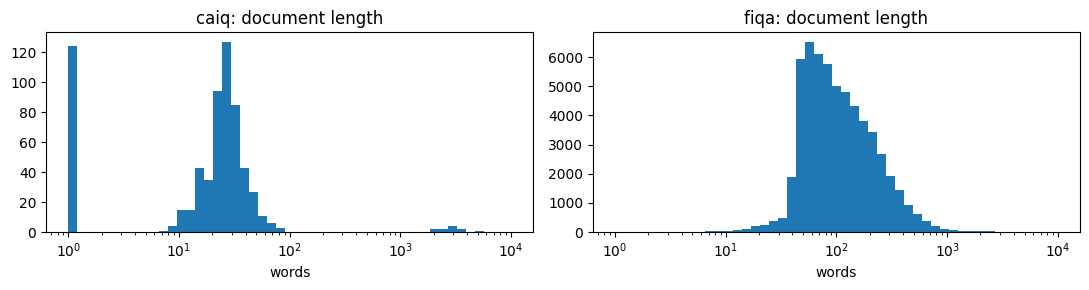

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    words = np.array([len(lab.tokenize(t)) for t in ds.bodies])
    ax.hist(words, bins=np.logspace(0, 4, 50))
    ax.set_xscale("log")
    ax.set_title(f"{ds.name}: document length")
    ax.set_xlabel("words")
fig.tight_layout()

In [4]:
for ds in DATASETS:
    qid = next(iter(ds.queries))
    best = ds.row[max(ds.qrels[qid], key=ds.qrels[qid].get)]
    texts = [ds.bodies[best]] if ds.titles[best].strip() in lab.PLACEHOLDER_TITLES else [ds.titles[best], ds.bodies[best]]
    print(f"{lab.NAMES[ds.name]}\n  question   {lab.cut(ds.queries[qid], 110)}")
    print("  relevant   " + "\n             ".join(lab.cut(t, 70) for t in texts) + "\n")

CAIQ
  question   For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approv…
  relevant   Present SpA — A&A-06.1: Is a risk-based corrective action plan to rem…
             Yes. Performed as part of ISO 27001:2013 standard certification.

FiQA
  question   How to deposit a cheque issued to an associate in my business into my business account?
  relevant   Have the check reissued to the proper payee.



<br><br>

## 2. From text to terms

Before we can search for anything, we must turn text into *terms*. We lowercase the text and remove accents (*normalization*), then split it into runs of letters and digits (*tokenization*), dropping punctuation and anything else that is not a Unicode letter or a digit. This process is called *text analysis*. We will add two more steps to it later: stopword removal in section 5 and stemming in section 8.

In [5]:
for s in ("Is data-at-rest encrypted (AES-256)?", "Café naïve ﬁnance: 401(k) or IRA?", "TLS_1.2 vs. TLS-1.3"):
    print(f"{s!r:40} -> {lab.tokenize(s)}")

'Is data-at-rest encrypted (AES-256)?'   -> ['is', 'data', 'at', 'rest', 'encrypted', 'aes', '256']
'Café naïve ﬁnance: 401(k) or IRA?'      -> ['cafe', 'naive', 'finance', '401', 'k', 'or', 'ira']
'TLS_1.2 vs. TLS-1.3'                    -> ['tls', '1', '2', 'vs', 'tls', '1', '3']


<br><br>

## 3. An inverted index

To efficiently match query terms to document terms, we index all document terms into an *inverted index*, which maps each term to the list of documents (*postings*) containing it. The resulting list is called a *posting list*. Our index is a *positional index*, which means that each posting additionally keeps the position of each occurrence of the term within the document. This enables efficient matching of *phrases* (sequences of terms).

In [6]:
ix = lab.index(caiq.bodies)
docs, tf = ix.postings("encryption")
print(f'"encryption" is in {len(docs)} of CAIQ\'s {ix.n} documents.')
print("  times per document:   " + " · ".join(f"doc {d} ×{n:.0f}" for d, n in zip(docs[:5], tf[:5])) + " …")
keys = ix.occurrences("encryption")[:5]
print("  first occurrences:    " + " · ".join(f"doc {k // lab.STRIDE} @{k % lab.STRIDE}" for k in keys) + " …")

a, b = ix.postings("encryption")[0], ix.postings("keys")[0]
docs, tf = ix.where([(0, "encryption"), (1, "keys")])  # "keys" one position after "encryption"
print(f"\nencryption AND keys   {len(np.intersect1d(a, b)):3d} documents")
print(f"encryption OR keys    {len(np.union1d(a, b)):3d} documents")
print(f'"encryption keys"     {len(docs):3d} documents, {tf.sum():.0f} times as a phrase')


def sizes(analyzer, before=None):
    """Each dataset's vocabulary (distinct terms) and words in all under analyzer; with before, under before → analyzer."""
    rows = []
    for ds in DATASETS:
        ixs = [lab.index(ds.bodies, a) for a in ([] if before is None else [before]) + [analyzer]]
        rows.append((lab.NAMES[ds.name], " → ".join(f"{len(ix.vocab):,}" for ix in ixs),
                     " → ".join(f"{ix.lengths.sum():,.0f}" for ix in ixs)))
    w1, w2 = (max(len(r[k]) for r in rows + [("", "distinct terms", "words in all")]) + 3 for k in (1, 2))
    print(f"{'':6s}{'distinct terms':>{w1}s}{'words in all':>{w2}s}")
    for name, terms, words in rows:
        print(f"{name:6s}{terms:>{w1}s}{words:>{w2}s}")

print()
sizes(lab.TOKENS)

"encryption" is in 53 of CAIQ's 644 documents.
  times per document:   doc 22 ×1 · doc 159 ×1 · doc 162 ×1 · doc 163 ×1 · doc 165 ×2 …
  first occurrences:    doc 22 @22 · doc 159 @24 · doc 162 @5 · doc 163 @12 · doc 165 @3 …

encryption AND keys    10 documents
encryption OR keys     55 documents
"encryption keys"       8 documents, 10 times as a phrase

         distinct terms   words in all
CAIQ              1,831         47,491
FiQA             77,486      8,271,209


<br><br>

## 4. Matching words

We now have the building blocks for the simplest ranking algorithm: count how many of the question's terms each document contains, the *term overlap* $\lvert T(q) \cap T(d) \rvert$, where $T(q)$ and $T(d)$ are the sets of distinct terms in the question $q$ and the document $d$.

                      CAIQ               FiQA         
matching words       0.016              0.079         


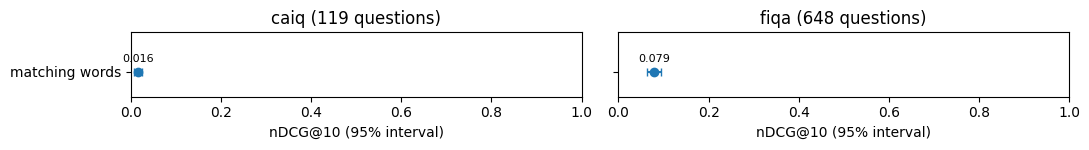

In [7]:
MATCH = {ds.name: lab.matching(ds, ds.bodies) for ds in DATASETS}  # how many of the question's words each document has
runs = {ds.name: {"matching words": lab.evaluate(ds, MATCH[ds.name])} for ds in DATASETS}
lab.plot_progress(runs);

In [8]:
lab.show(caiq, caiq.qids[0], {"matching words": MATCH["caiq"]})

Question  For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approv…

matching words · nDCG@10 0.000 · none of the top 5 relevant
  1  ·  Yes. Yes. Audit logs stored in PostgreSQL with database-level ac…
  2  ·  Yes. Yes. The organization maintains incident response procedure…
  3  ·  NA. Cloud-hosted on DigitalOcean. Physical datacenter asset trac…
  4  ·  Partial. People Security Policy defines endpoint security requir…
  5  ·  Yes. Incident Response Plan defines customer notification proced…



<br><br>

## 5. Stopwords

The above algorithm has the following problem: very common terms such as "the", "be", "to" and "of" occur in almost every document, so they add to the overlap of nearly every document while carrying almost no information. These terms are called *stopwords*. We add stopword removal to the text analysis, so that they no longer count.

Stopwords in "Are encryption keys rotated and are encrypted backups stored offsite?":  are, and, are

          distinct terms            words in all
CAIQ       1,831 → 1,777         47,491 → 42,407
FiQA     77,486 → 77,422   8,271,209 → 4,938,427



FiQA  nDCG@10 0.079 → 0.106  ·  104 questions better, 53 worse (of 648)  ·  5 jump from below 0.3 to above 0.7

Question  How to categorize credit card payments?

matching words · nDCG@10 0.000 · none of the top 5 relevant
  1  ·  8 hard inquiries spread over two years is not a negative factor,…
  2  ·  I have credit card debt of about $5000 That's the answer right t…
  3  ·  The answer depends on how much you spend every month. The DTI is…
  4  ·  > How do I guarantee that people are held liable for damages and…
  5  ·  "What you have is usually called a pre-paid credit card. You pay…

+ stopwords · nDCG@10 1.000 · 1 of the top 5 relevant
  1  ✓  "Using the Transfer category is the best place to put these cate…
  2  ·  8 hard inquiries spread over two years is not a negative factor,…
  3  ·  I have credit card debt of about $5000 That's the answer right t…
  4  ·  The answer depends on how much you spend every month. The DTI is…
  5  ·  This will have no effect on your credit score. E

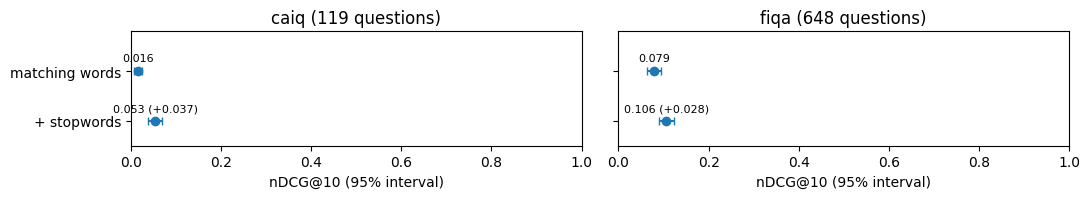

In [9]:
STOP = lab.Analyzer(stopwords=True)  # tokens without stopwords
text = "Are encryption keys rotated and are encrypted backups stored offsite?"
print(f'Stopwords in "{text}":  ' + ", ".join(w for w in lab.tokenize(text) if w in lab.STOPWORDS) + "\n")
sizes(STOP, before=lab.TOKENS)
print()

MATCH_STOP = {ds.name: lab.matching(ds, ds.bodies, STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ stopwords"] = lab.evaluate(ds, MATCH_STOP[ds.name])
example = lab.example(fiqa, runs["fiqa"]["matching words"], runs["fiqa"]["+ stopwords"])
lab.show(fiqa, example, {"matching words": MATCH["fiqa"], "+ stopwords": MATCH_STOP["fiqa"]})
lab.plot_progress(runs);

<br><br>

## 6. TF-IDF

Removing stopwords helps, but every remaining term still counts the same: a match on "data" counts as much as a match on "pseudonymization".

Therefore, in addition to ranking in proportion to *term frequency* (how often a term occurs in a document), we want to give less weight to common terms and more weight to rare terms. This is captured by *inverse document frequency*, roughly $\ln(N / \mathrm{df}(t))$ for $N$ documents of which $\mathrm{df}(t)$ contain the term $t$. We use the exact form

$$\mathrm{idf}(t) = \ln\left(1 + \frac{N - \mathrm{df}(t) + 0.5}{\mathrm{df}(t) + 0.5}\right),$$

which never goes below zero. Combining term frequency and inverse document frequency gives us the TF-IDF ranking algorithm

$$\mathrm{tfidf}(q, d) = \sum_{t \in T(q)} \mathrm{tf}(t, d) \cdot \mathrm{idf}(t),$$

where $\mathrm{tf}(t, d)$ is how many times the term $t$ occurs in the document $d$.

CAIQ  nDCG@10 0.053 → 0.030  ·  10 questions better, 44 worse (of 119)

Question  For Present SpA: Are regular security awareness training updates provided?

+ stopwords · nDCG@10 0.369 · 1 of the top 5 relevant
  1  ·  Yes. Yes. Audit logs stored in PostgreSQL with database-level ac…
  2  ✓  Present SpA — HRS-11.1: Is a security awareness training program…
  3  ·  NA. Yes. Automated quarterly access reviews via Fimil-Ops endpoi…
  4  ·  Yes. Operator role is the highest privilege level (100). Imperso…
  5  ·  Yes. Change Management Policy defines Emergency change type with…

tf-idf · nDCG@10 0.145 · none of the top 5 relevant
  1  ·  NA. Cloud-hosted on DigitalOcean. Physical hardware relocation i…
  2  ·  Yes. Operator role is the highest privilege level (100). Imperso…
  3  ·  Yes. Change Management Policy defines Emergency change type with…
  4  ·  Yes. Yes. Audit logs stored in PostgreSQL with database-level ac…
  5  ·  NA. Yes. Automated quarterly access reviews via Fimil-Ops end

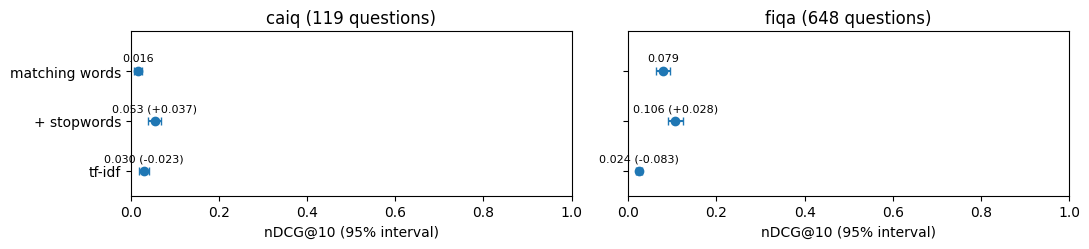

In [10]:
TFIDF = {ds.name: lab.tfidf(ds, ds.bodies, STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["tf-idf"] = lab.evaluate(ds, TFIDF[ds.name])
example = lab.example(caiq, runs["caiq"]["+ stopwords"], runs["caiq"]["tf-idf"], broken=True)
lab.show(caiq, example, {"+ stopwords": MATCH_STOP["caiq"], "tf-idf": TFIDF["caiq"]})
lab.plot_progress(runs);

In [11]:
print(f"tf-idf's top 3 for this question:\n\n{'':4s}{'terms':>7s}   most frequent")
for rank, d in enumerate(lab.top(caiq, example, TFIDF["caiq"], 3), 1):
    terms = STOP.terms(caiq.bodies[caiq.row[d]])[0]
    common = sorted(set(terms), key=lambda t: (-terms.count(t), t))[:5]  # ties in alphabetical order
    print(f"{rank:4d}{len(terms):7,d}   " + " · ".join(f"{t} ×{terms.count(t)}" for t in common))

tf-idf's top 3 for this question:

      terms   most frequent
   1  2,468   production ×571 · environments ×285 · non ×285 · present ×285 · separated ×285
   2  2,985   trained ×251 · awareness ×250 · deploy ×250 · least ×250 · octopus ×250
   3  2,981   security ×229 · audit ×228 · automated ×228 · reviewed ×228 · events ×227


<br><br>

## 7. BM25

TF-IDF performed worse than plain term overlap. It has two problems. The score grows linearly with term frequency, so the tenth occurrence of a term adds as much as the first. And long documents contain more terms and more occurrences, so they match more of everything. BM25 fixes both:

- Term frequency saturation: each extra occurrence adds less than the one before, and the contribution approaches a limit. The parameter **k1** sets how fast it saturates.

- Document length normalization: a document's term frequency is adjusted relative to what is expected for an average document of the same length. The parameter **b** controls the strength of this effect (0 = not at all, 1 = fully).

BM25, the standard lexical ranking function of many production retrieval systems, scores a document by

$$\mathrm{BM25}(q, d) = \sum_{t \in T(q)} \mathrm{idf}(t) \cdot \frac{\mathrm{tf}(t, d)\,(k_1 + 1)}{\mathrm{tf}(t, d) + k_1 \left(1 - b + b\,\frac{\lvert d \rvert}{\mathrm{avgdl}}\right)},$$

where $\lvert d \rvert$ is the document's length in terms, $\mathrm{avgdl}$ the average length, and by default $k_1 = 1.2$ and $b = 0.75$. As $\mathrm{tf}(t, d)$ grows, the fraction approaches $k_1 + 1$.

CAIQ  nDCG@10 0.030 → 0.224  ·  98 questions better, 0 worse (of 119)

Question  For Fimil: Are metrics for vulnerability identification and remediation established?

tf-idf · nDCG@10 0.000 · none of the top 5 relevant
  1  ·  NA. Yes. Automated quarterly access reviews via Fimil-Ops endpoi…
  2  ·  Yes. Yes. The organization maintains incident response procedure…
  3  ·  Yes. Incident Response Plan defines customer notification proced…
  4  ·  Yes. During annual ISO 27001 re- certification process or based…
  5  ·  Yes. Yes. Audit logs stored in PostgreSQL with database-level ac…

bm25 · nDCG@10 0.640 · 4 of the top 5 relevant
  1  ✓  Present SpA — TVM-10.1: Are metrics for vulnerability identifica…
  2  ·  Present SpA — SEF-05.1: Are information security incident metric…
  3  ✓  Present SpA — TVM-08.1: Is vulnerability remediation prioritized…
  4  ✓  Fimil — TVM-05.1: Are processes to identify updates for applicat…
  5  ✓  Fimil — TVM-03.1: Are processes to enable scheduled and emer

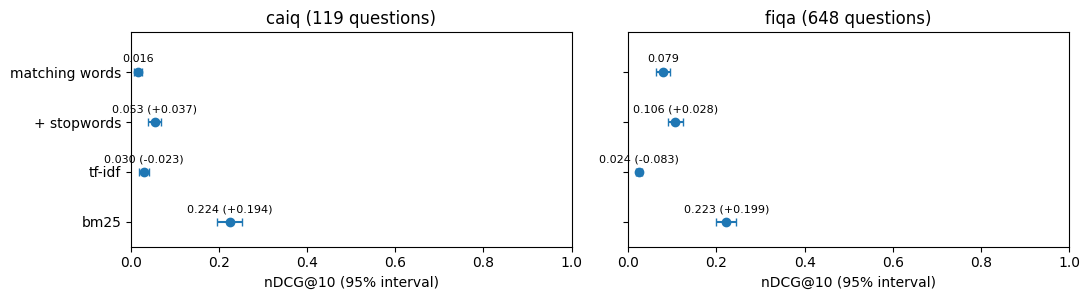

In [12]:
BM25 = {ds.name: lab.bm25(ds, ds.bodies, analyzer=STOP) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["bm25"] = lab.evaluate(ds, BM25[ds.name])
example = lab.example(caiq, runs["caiq"]["tf-idf"], runs["caiq"]["bm25"])
lab.show(caiq, example, {"tf-idf": TFIDF["caiq"], "bm25": BM25["caiq"]})
lab.plot_progress(runs);

CAIQ       b = 0  b = 0.25   b = 0.5  b = 0.75     b = 1
k1 0.6     0.049     0.188     0.216     0.233     0.243
k1 1.2     0.043     0.182     0.208     0.224     0.243
k1 2.0     0.042     0.165     0.195     0.217     0.238

FiQA       b = 0  b = 0.25   b = 0.5  b = 0.75     b = 1
k1 0.6     0.166     0.215     0.221     0.225     0.217
k1 1.2     0.165     0.214     0.221     0.223     0.201
k1 2.0     0.152     0.204     0.218     0.210     0.186



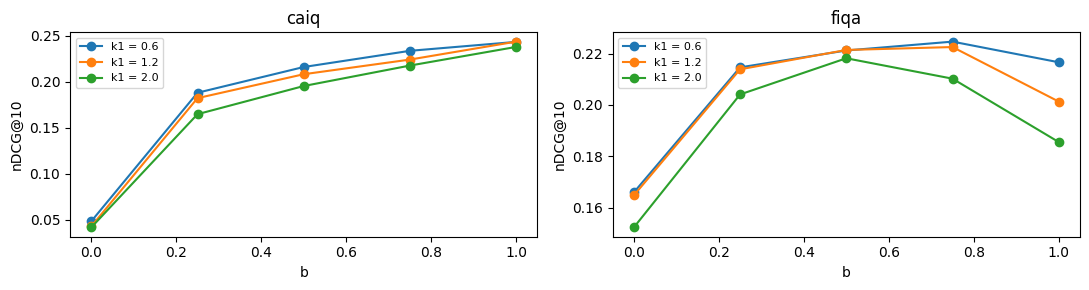

In [13]:
K1, B = (0.6, 1.2, 2.0), (0, 0.25, 0.5, 0.75, 1)
grid = {(ds.name, k1, b): np.mean(list(lab.evaluate(ds, lab.bm25(ds, ds.bodies, k1, b, analyzer=STOP)).values()))
        for ds in DATASETS for k1 in K1 for b in B}
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    for k1 in K1:
        ax.plot(B, [grid[ds.name, k1, b] for b in B], marker="o", label=f"k1 = {k1}")
    ax.set_title(ds.name)
    ax.set_xlabel("b")
    ax.set_ylabel("nDCG@10")
    ax.legend(fontsize=8)
fig.tight_layout()
for ds in DATASETS:
    print(f"{lab.NAMES[ds.name]:6s}" + "".join(f"{'b = ' + str(b):>10s}" for b in B))
    for k1 in K1:
        print(f"k1 {k1:<3}" + "".join(f"{grid[ds.name, k1, b]:10.3f}" for b in B))
    print()

<br><br>

## 8. Stemming

So far, each term had to match exactly, so a question about "rotating encryption keys" does not match "key rotation".

A *stemmer* reduces each term to a common stem: "rotating", "rotation" and "rotated" all become "rotat", and "encryption" and "encrypted" both become "encrypt". We add the **Snowball stemmer** to the text analysis pipeline.

Stemming raises *recall* (more relevant documents match) at some cost in *precision*, since unrelated words can share a stem. This is generally desirable, but too aggressive stemming algorithms can hurt precision too much. The Snowball stemmer is a good starting point, with support for many languages.

Stemmed:  encryption → encrypt · keys → key · rotated → rotat · encrypted → encrypt · backups → backup · stored → store · offsite → offsit

          distinct terms            words in all
CAIQ       1,777 → 1,290         42,407 → 42,407
FiQA     77,422 → 56,918   4,938,427 → 4,938,427



CAIQ  nDCG@10 0.224 → 0.259  ·  61 questions better, 41 worse (of 119)

Question  For Octopus Deploy: Are policies and procedures established and mechanisms configured and implemented to prot…
          ✓✓ most relevant (grade 2), ✓ relevant (grade 1)

bm25 · nDCG@10 0.000 · none of the top 5 relevant
  1  ·   Fimil — IVS-03.3: Are communications between environments restri…
  2  ·   Yes. Operator role is the highest privilege level (100). Imperso…
  3  ·   NA. Cloud-hosted on DigitalOcean. Physical datacenter asset trac…
  4  ·   Yes. Change Management Policy defines Emergency change type with…
  5  ·   Fimil — IVS-01.1: Are infrastructure and virtualization security…

+ stemming · nDCG@10 0.415 · 1 of the top 5 relevant
  1  ·   NA. Cloud-hosted on DigitalOcean. Physical datacenter asset trac…
  2  ✓✓  Octopus Deploy — IVS-12.3: Are policies and procedures establish…
  3  ·   Fimil — IVS-03.3: Are communications between environments restri…
  4  ·   Yes. Operator role is the highest 

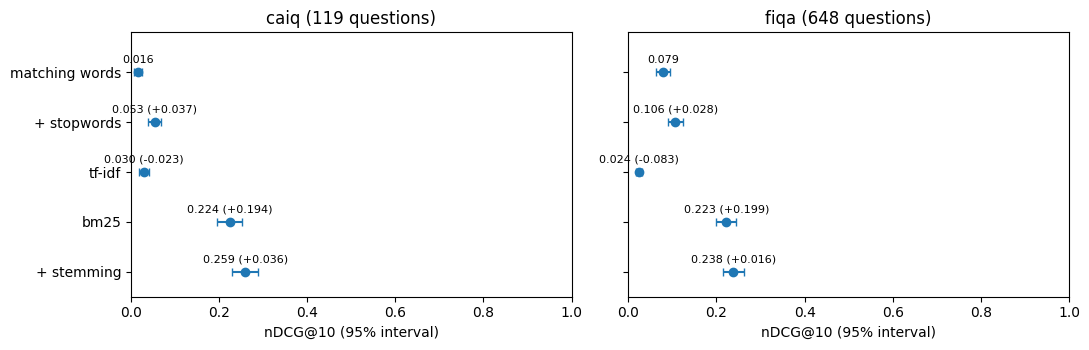

In [14]:
STEM = lab.Analyzer(stopwords=True, stemming=True)  # ... and each term reduced to its stem
text = "Are encryption keys rotated and are encrypted backups stored offsite?"
terms, positions = STEM.terms(text)
print("Stemmed:  " + " · ".join(f"{lab.tokenize(text)[p]} → {t}" for t, p in zip(terms, positions)) + "\n")
sizes(STEM, before=STOP)
print()

STEMMED = {ds.name: lab.bm25(ds, ds.bodies, analyzer=STEM) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ stemming"] = lab.evaluate(ds, STEMMED[ds.name])
example = lab.example(caiq, runs["caiq"]["bm25"], runs["caiq"]["+ stemming"])
lab.show(caiq, example, {"bm25": BM25["caiq"], "+ stemming": STEMMED["caiq"]})
lab.plot_progress(runs);

<br><br>

## 9. Multi-field BM25

Real documents are structured in multiple fields: usually at least a title and a body of text. A match in the title generally matters more than a match somewhere in a long body. Different fields also have different statistics and semantic meaning, so we might want to compute BM25 for each field separately and weight them differently.

We add a second BM25 score for the title, so that the multi-field score is

$$s(q, d) = \mathrm{BM25}(q, \mathrm{body}_d) + \mathrm{BM25}(q, \mathrm{title}_d),$$

where $\mathrm{body}_d$ and $\mathrm{title}_d$ are the document's two fields. For CAIQ, we found that combining the IDF statistics for the two fields resulted in better ranking quality, so both scores use one idf, with $\mathrm{df}(t)$ counted over title and body together; on other datasets the opposite could be true. FiQA has very few titles. Always tune your ranking function on a representative sample of data for your use case.

nDCG@10 of body + title   IDF per field   IDF over title and body together
CAIQ                              0.513                              0.549


FiQA                              0.238                              0.238

                      CAIQ               FiQA         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)


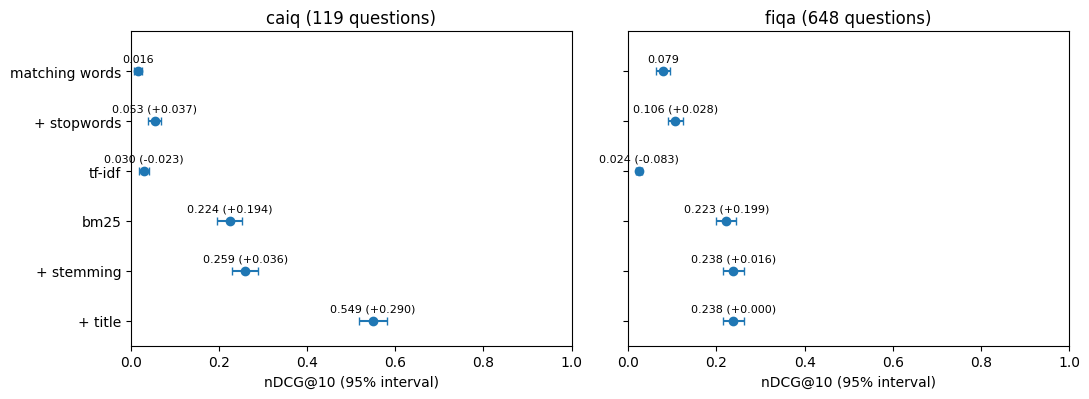

In [15]:
own = {ds.name: lab.bm25(ds, ds.titles, analyzer=STEM) for ds in DATASETS}  # the title's IDF from the titles alone
BODY = {ds.name: lab.bm25(ds, ds.bodies, idf_texts=ds.title_body, analyzer=STEM) for ds in DATASETS}  # from here on, every
TITLE = {ds.name: lab.bm25(ds, ds.titles, idf_texts=ds.title_body, analyzer=STEM) for ds in DATASETS}  # field's IDF is the same
print(f"{'nDCG@10 of body + title':24s}{'IDF per field':>15s}{'IDF over title and body together':>35s}")
for ds in DATASETS:
    per_field = lab.evaluate(ds, STEMMED[ds.name] + own[ds.name])
    shared = lab.evaluate(ds, BODY[ds.name] + TITLE[ds.name])
    print(f"{lab.NAMES[ds.name]:24s}{np.mean(list(per_field.values())):15.3f}{np.mean(list(shared.values())):35.3f}")
    runs[ds.name]["+ title"] = shared
print()
del own
lab.plot_progress(runs);

In [16]:
example = lab.example(caiq, runs["caiq"]["+ stemming"], runs["caiq"]["+ title"])
lab.show(caiq, example, {"+ stemming": STEMMED["caiq"], "+ title": BODY["caiq"] + TITLE["caiq"]})

CAIQ  nDCG@10 0.259 → 0.549  ·  117 questions better, 1 worse (of 119)  ·  6 jump from below 0.3 to above 0.7

Question  For Realigned Technologies: Do you have technical capabilities to enforce tenant data retention policies?

+ stemming · nDCG@10 0.130 · 1 of the top 5 relevant
  1  ·  NA. Cloud-hosted on DigitalOcean. Physical datacenter asset trac…
  2  ·  NA. For the purpose of the questionnaire the question is not app…
  3  ·  Yes. During annual ISO 27001 re- certification process or based…
  4  ✓  Fimil — DSP-16.1: Do data retention, archiving, and deletion pra…
  5  ·  Fimil — HRS-05.1: Are return procedures of organizationally-owne…

+ title · nDCG@10 0.775 · 4 of the top 5 relevant
  1  ✓  Octopus Deploy — BCR-11.1: Do you have technical capabilities to…
  2  ✓  Fimil — DSP-16.1: Do data retention, archiving, and deletion pra…
  3  ✓  Realigned Technologies — EKM-03.1: Do you encrypt tenant data at…
  4  ✓  Realigned Technologies — STA-05.5: Do you have the capability to…
  5

<br><br>

## 10. Synonyms

Stemming creates an equivalence class of slightly different forms of the same word. In the same way, we would like to equate different ways of writing the same concept, like "single sign on" and "SSO". A *synonym list* can close this *vocabulary mismatch* by *query expansion*: at query time, a synonym group $g$ that occurs in the question scores as its best-matching phrase in each document $d$,

$$\mathrm{score}_g(d) = \max_{a \in g} \mathrm{BM25}(a, d),$$

where $a$ runs over the group's phrases, the question's own wording among them.

With current generation vector search systems, it rarely makes sense to use generic off-the-shelf synonym databases, but domain-specific synonym lists tailored to specific query patterns and data, derived from real users interacting with your system, can make a significant difference.

In [17]:
ANALYZER = lab.Analyzer(stopwords=True, stemming=True, synonyms=lab.synonyms())  # every lexical step from here on
print(f"{len(ANALYZER.groups)} synonym groups, six of them:")
for group in ANALYZER.groups[:6]:
    print("  " + "  =  ".join(" ".join(p) for p in group))
print("\nQuestions with a synonym phrase:   " + "   ·   ".join(
    f"{lab.NAMES[ds.name]} {sum(bool(ANALYZER.query(ds.queries[q])[1]) for q in ds.qids)} of {len(ds.qids)}" for ds in DATASETS))


def expansions(question):
    """Each synonym phrase in question as the question writes it -> the other phrases of its group as the synonym list
    writes them."""
    tokens = lab.tokenize(question)
    out = {}
    for g, i, n in ANALYZER.concepts(tokens):
        own = [lab.stem(t) for t in tokens[i:i + n]]
        out[" ".join(tokens[i:i + n])] = [" ".join(p) for p in ANALYZER.groups[g] if [lab.stem(t) for t in p] != own]
    return out


def print_expansions(question):
    found = expansions(question)
    width = max(map(len, found))
    for own, others in found.items():
        print(f"    {own:{width}s}  →  also matches  {' · '.join(others)}")


print(f"\nOne question, expanded:\n  {lab.cut(caiq.queries[caiq.qids[0]], 110)}")
print_expansions(caiq.queries[caiq.qids[0]])

53 synonym groups, six of them:
  non resident  =  nonresident
  exchange rate  =  fx rate  =  currency exchange rate
  octopus deploy  =  octopus  =  octopusdeploy
  dlp  =  data loss prevention  =  data leak prevention  =  data leakage prevention
  bcp  =  business continuity plan  =  business continuity planning  =  business continuity plans  =  bc plan
  encryption key  =  encryption keys  =  cryptographic key  =  cryptographic keys  =  crypto keys  =  crypto key

Questions with a synonym phrase:   CAIQ 79 of 119   ·   FiQA 249 of 648

One question, expanded:
  For Fimil: Is a risk-based corrective action plan to remediate audit findings established, documented, approv…
    established  →  also matches  set up
    approved     →  also matches  authorize · sanction


CAIQ  nDCG@10 0.549 → 0.561  ·  25 questions better, 12 worse (of 119)

The synonyms in this question:
    octopus deploy  →  also matches  octopus · octopusdeploy
    authorized      →  also matches  approve · sanction

Question  For Octopus Deploy: Is mobile code authorized before its installation and use, and the code configuration che…

+ title · nDCG@10 0.316 · 2 of the top 5 relevant
  1  ·  Octopus Deploy — IAM-06.2: Are controls in place to prevent unau…
  2  ·  Octopus Deploy — BCR-10.1: Are policies and procedures establish…
  3  ✓  Octopus Deploy — MOS-03.1: Do you have a policy enforcement capa…
  4  ✓  Octopus Deploy — CCC-04.1: Do you have controls in place to rest…
  5  ·  Octopus Deploy — IVS-12.1: Are policies and procedures establish…

+ synonyms · nDCG@10 0.485 · 2 of the top 5 relevant
  1  ✓  Octopus Deploy — MOS-03.1: Do you have a policy enforcement capa…
  2  ·  Fimil — CCC-02.1: Is a defined quality change control, approval…
  3  ·  Octopus Deploy — IAM-06.2: A

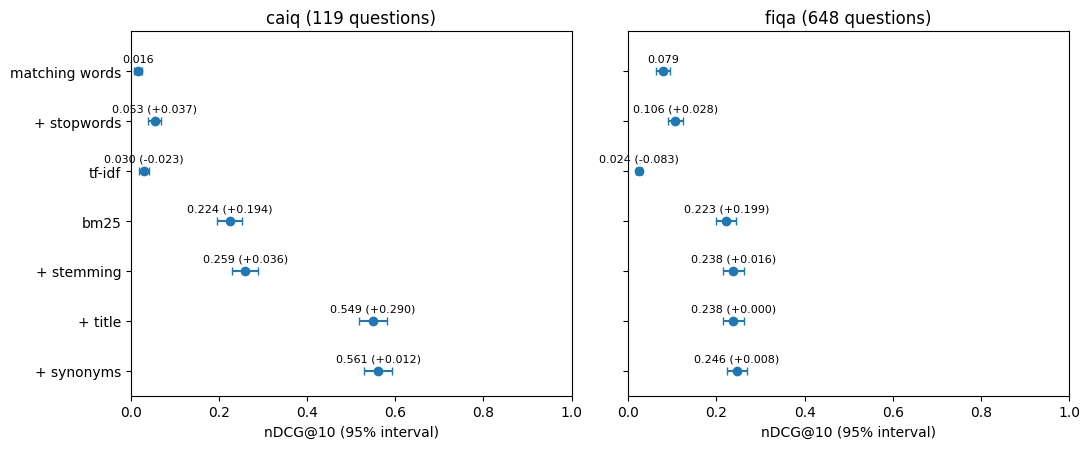

In [18]:
NO_SYNONYMS = {ds.name: BODY[ds.name] + TITLE[ds.name] for ds in DATASETS}
BODY = {ds.name: lab.bm25(ds, ds.bodies, idf_texts=ds.title_body, analyzer=ANALYZER) for ds in DATASETS}
TITLE = {ds.name: lab.bm25(ds, ds.titles, idf_texts=ds.title_body, analyzer=ANALYZER) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["+ synonyms"] = lab.evaluate(ds, BODY[ds.name] + TITLE[ds.name])
example = lab.example(caiq, runs["caiq"]["+ title"], runs["caiq"]["+ synonyms"])
print("The synonyms in this question:")
print_expansions(caiq.queries[example])
print()
lab.show(caiq, example, {"+ title": NO_SYNONYMS["caiq"], "+ synonyms": BODY["caiq"] + TITLE["caiq"]})


def says(i, phrase):
    """Whether document row i of CAIQ (title and body) contains phrase, compared stem by stem."""
    want = [lab.stem(t) for t in lab.tokenize(phrase)]
    have = [lab.stem(t) for t in lab.tokenize(f"{caiq.titles[i]} {caiq.bodies[i]}")]
    return any(have[k:k + len(want)] == want for k in range(len(have)))


for rank, d in enumerate(lab.top(caiq, example, BODY["caiq"] + TITLE["caiq"], 5), 1):
    i = caiq.row[d]
    for own, others in expansions(caiq.queries[example]).items():
        used = [p for p in others if says(i, p)]
        if caiq.qrels[example].get(d, 0) and used and not says(i, own):
            print(f'Rank {rank} with synonyms is relevant and says "{used[0]}" where the question says "{own}".')
print()
lab.plot_progress(runs);

<br><br>

## 11. Saturated BM25

BM25 saturates term frequency within a field, but the overall BM25 scores are unbounded, they can range to some fairly high values. In CAIQ, some long answers repeat the same few sentences and rank high for many questions this way.

We would like all component scores in a ranking algorithm to be normalized to the same scale (in practice, between 0 and 1) so that we can combine them in linear combinations. In practice, we have found good results by saturating each field's BM25 score $x$ as well, to $x / (\kappa + x)$, which is normalized to 0-1 and reaches one half at $x = \kappa$. The saturated score of a document sums its two fields,

$$s(q, d) = \sum_{f \in \{\mathrm{body},\, \mathrm{title}\}} \frac{\mathrm{BM25}_f(q, d)}{\kappa + \mathrm{BM25}_f(q, d)},$$

where $\mathrm{BM25}_f(q, d)$ is the BM25 score of field $f$.

CAIQ  nDCG@10 0.561 → 0.542  ·  39 questions better, 63 worse (of 119)



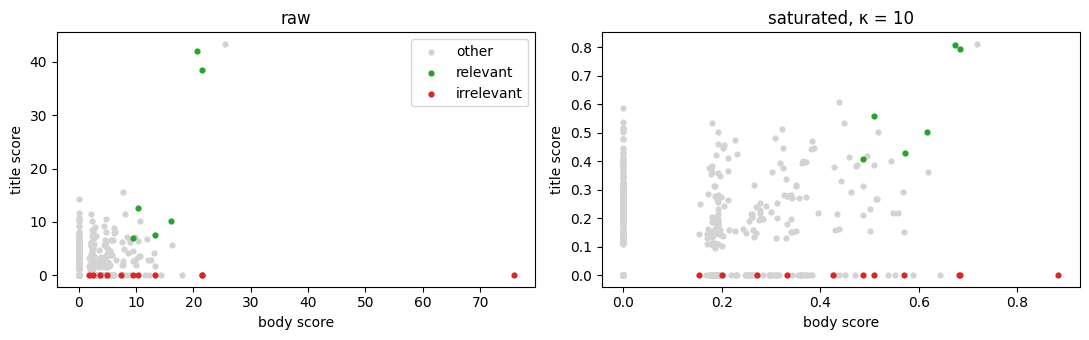

In [19]:
def saturated(ds, kappa):
    return BODY[ds.name] / (kappa + BODY[ds.name]) + TITLE[ds.name] / (kappa + TITLE[ds.name])

example = lab.example(caiq, runs["caiq"]["+ synonyms"], lab.evaluate(caiq, saturated(caiq, 10)))
body, title = BODY["caiq"][caiq.qrow[example]], TITLE["caiq"][caiq.qrow[example]]
words = [lab.tokenize(t) for t in caiq.bodies]  # long answers whose last 200 words are under 9% distinct: repeated sentences
is_irr = np.array([len(w) > 200 and len(set(w[-200:])) < 18 for w in words])
is_rel = np.array([caiq.qrels[example].get(d, 0) > 0 for d in caiq.ids])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, f) in zip(axes, (("raw", lambda x: x), ("saturated, κ = 10", lambda x: x / (10 + x)))):
    for mask, label, color in ((~is_irr & ~is_rel, "other", "lightgrey"), (is_rel, "relevant", "C2"), (is_irr, "irrelevant", "C3")):
        ax.scatter(f(body[mask]), f(title[mask]), s=12, color=color, label=label)
    ax.set_xlabel("body score")
    ax.set_ylabel("title score")
    ax.set_title(name)
axes[0].legend()
fig.tight_layout()

κ                   2      5     10     25     50    100
CAIQ nDCG@10    0.523  0.534  0.542  0.567  0.567  0.563

κ = 25 scores best; both datasets use it from here on.



                      CAIQ               FiQA         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)
+ synonyms           0.561 (+0.012)     0.246 (+0.008)
saturated            0.567 (+0.006)     0.246 (+0.000)


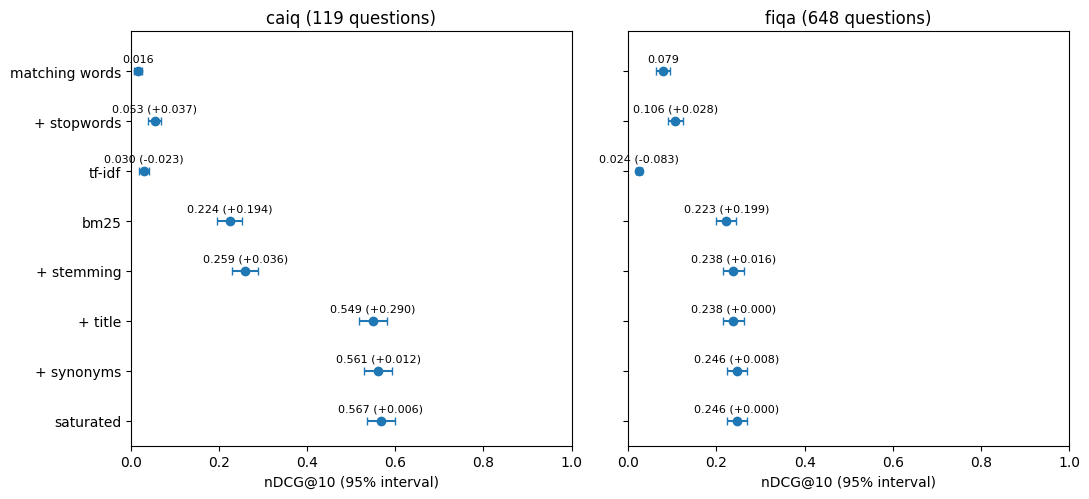

In [20]:
grid = {kappa: np.mean(list(lab.evaluate(caiq, saturated(caiq, kappa)).values())) for kappa in (2, 5, 10, 25, 50, 100)}
print("κ             " + "".join(f"{k:>7}" for k in grid))
print("CAIQ nDCG@10  " + "".join(f"{v:7.3f}" for v in grid.values()))
kappa = max(grid, key=grid.get)
print(f"\nκ = {kappa} scores best; both datasets use it from here on.\n")
for ds in DATASETS:
    runs[ds.name]["saturated"] = lab.evaluate(ds, saturated(ds, kappa))
lab.plot_progress(runs);

In [21]:
lab.show(caiq, example, {"+ synonyms": BODY["caiq"] + TITLE["caiq"], "saturated": saturated(caiq, kappa)})

Question  For Octopus Deploy: Are controls in place to prevent unauthorized access to tenant application, program, or o…

+ synonyms · nDCG@10 0.580 · 3 of the top 5 relevant
  1  ·  NA. For the purpose of the questionnaire the question is not app…
  2  ✓  Octopus Deploy — IAM-06.1: Are controls in place to prevent unau…
  3  ✓  Realigned Technologies — IAM-06.1: Are controls in place to prev…
  4  ✓  Octopus Deploy — IAM-02.1: Do you have controls in place ensurin…
  5  ·  Octopus Deploy — CCC-04.1: Do you have controls in place to rest…

saturated · nDCG@10 0.832 · 4 of the top 5 relevant
  1  ✓  Octopus Deploy — IAM-06.1: Are controls in place to prevent unau…
  2  ✓  Realigned Technologies — IAM-06.1: Are controls in place to prev…
  3  ·  NA. For the purpose of the questionnaire the question is not app…
  4  ✓  Octopus Deploy — IAM-02.1: Do you have controls in place ensurin…
  5  ✓  Octopus Deploy — IAM-08.1: Do you document how you grant, approv…



<br><br>

## 12. Phrase match boosting

So far, each document is a *bag of words*: the order of the terms does not matter, so "data at rest" and "rest data" score the same. The positional index from section 3 lets us use *proximity*, through the phrase score

$$\mathrm{phrase} = \frac{\text{question's word pairs that are neighbours in the document}}{\text{question's word pairs}},$$

which we add to the saturated score from section 11, counting a phrase in the title twice as much as one in the body,

$$\mathrm{score} = \mathrm{saturated} + 0.2 \left( \tfrac{1}{2}\,\mathrm{phrase}_{\text{body}} + \mathrm{phrase}_{\text{title}} \right),$$

with the weight 0.2 chosen with the plot below.

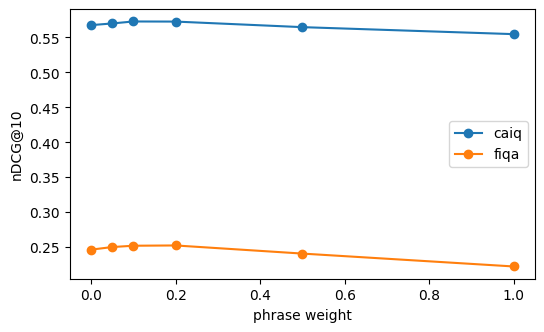

In [22]:
PHRASE_BODY = {ds.name: lab.phrase(ds, ds.bodies, ANALYZER) for ds in DATASETS}
PHRASE_TITLE = {ds.name: lab.phrase(ds, ds.titles, ANALYZER) for ds in DATASETS}
PHRASE = {n: 0.5 * PHRASE_BODY[n] + PHRASE_TITLE[n] for n in PHRASE_BODY}

def lexical(ds, w=0.2):
    return saturated(ds, kappa) + w * PHRASE[ds.name]

weights = (0, 0.05, 0.1, 0.2, 0.5, 1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    ax.plot(weights, [np.mean(list(lab.evaluate(ds, lexical(ds, w)).values())) for w in weights], marker="o", label=ds.name)
ax.set_xlabel("phrase weight")
ax.set_ylabel("nDCG@10")
ax.legend();

                      CAIQ               FiQA         
matching words       0.016              0.079         
+ stopwords          0.053 (+0.037)     0.106 (+0.028)
tf-idf               0.030 (-0.023)     0.024 (-0.083)
bm25                 0.224 (+0.194)     0.223 (+0.199)
+ stemming           0.259 (+0.036)     0.238 (+0.016)
+ title              0.549 (+0.290)     0.238 (+0.000)
+ synonyms           0.561 (+0.012)     0.246 (+0.008)
saturated            0.567 (+0.006)     0.246 (+0.000)
+ phrase             0.572 (+0.005)     0.252 (+0.006)


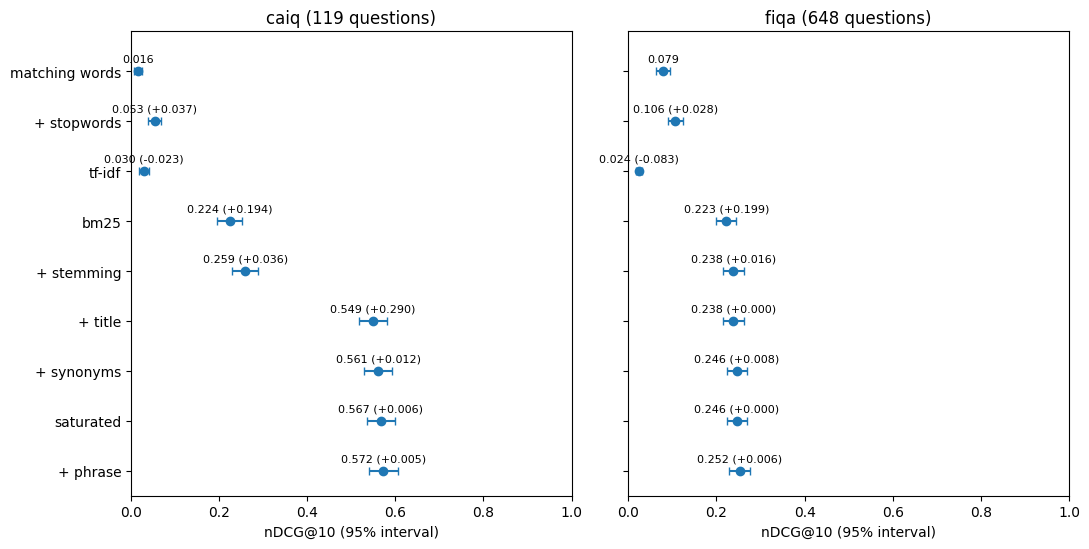

In [23]:
for ds in DATASETS:
    runs[ds.name]["+ phrase"] = lab.evaluate(ds, lexical(ds))
lab.plot_progress(runs);

In [24]:
gain = {q: runs["fiqa"]["+ phrase"][q] - runs["fiqa"]["saturated"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
lab.show(fiqa, example, {"saturated": saturated(fiqa, kappa), "+ phrase": lexical(fiqa)})

Question  What are some well known or well regarded arguments against investing?

saturated · nDCG@10 0.387 · 1 of the top 5 relevant
  1  ·  On the contrary. Outsourcing to India and investing in India in…
  2  ✓  "I think you're confusing risk analysis (that is what you quoted…
  3  ·  Some financial planners would not advise one way or the other on…
  4  ·  I can understand the argument that it's not a good allocation of…
  5  ·  ">Good luck arguing that in court while defending non-payment of…

+ phrase · nDCG@10 0.818 · 1 of the top 5 relevant
  1  ✓  "I think you're confusing risk analysis (that is what you quoted…
  2  ·  On the contrary. Outsourcing to India and investing in India in…
  3  ·  I can understand the argument that it's not a good allocation of…
  4  ·  ">Good luck arguing that in court while defending non-payment of…
  5  ·  Some financial planners would not advise one way or the other on…



<br><br>

## 13. Learning to rank

The current ranking function combines several scores (body, title, phrase) using linear weights chosen by hand. Learning to rank learns these weights from relevance judgments in the data instead.

Each question's top 50 documents become training examples, with the different scores we have defined so far used as *features* $x_1, \dots, x_n$ in the learning model. A linear model trained with LambdaRank, which optimizes the ranking directly, learns one weight $w_j$ per feature,

$$\mathrm{score} = \sum_j w_j \, x_j.$$

LightGBM instead learns many small decision trees, each splitting on the features, so that it can combine features in nonlinear ways,

$$\mathrm{score} = \sum_m \mathrm{tree}_m(x_1, \dots, x_n).$$

To measure honestly, we split the data into 5 shards, train on 4 shards of questions at a time and test on the remaining one (5-fold *cross-validation*). The feature importance table shows which features matter:

In [25]:
import lightgbm as lgb

LEX_TOP = {ds.name: lab.topk(ds, lexical(ds), 50) for ds in DATASETS}
FEATURES = ("bm25 body", "bm25 title", "phrase body", "phrase title")

def parts(ds):
    """The lexical formula's parts, as the formula uses them."""
    n = ds.name
    return [BODY[n] / (kappa + BODY[n]), TITLE[n] / (kappa + TITLE[n]), PHRASE_BODY[n], PHRASE_TITLE[n]]

RAW = {ds.name: np.stack([np.take_along_axis(p, LEX_TOP[ds.name], 1) for p in parts(ds)], -1) for ds in DATASETS}
SCALE = {n: (x.mean((0, 1)), np.maximum(x.std((0, 1)), 1e-9)) for n, x in RAW.items()}
X = {n: (x - SCALE[n][0]) / SCALE[n][1] for n, x in RAW.items()}
Y = {ds.name: lab.labels(ds, LEX_TOP[ds.name]) for ds in DATASETS}
GBM = dict(objective="lambdarank", learning_rate=0.05, num_leaves=7, deterministic=True, force_row_wise=True, verbose=-1)

def linear(x, y, ideal, x_test):
    return x_test @ lab.lambdarank(x, y, ideal)

def lightgbm(x, y, ideal, x_test):
    model = lgb.train(GBM, lgb.Dataset(x.reshape(-1, x.shape[-1]), y.reshape(-1), group=[x.shape[1]] * len(x)), 200)
    return model.predict(x_test.reshape(-1, x.shape[-1])).reshape(x_test.shape[:2])

LTR = {fit.__name__: {ds.name: lab.cross_validate(ds, X[ds.name], Y[ds.name], fit) for ds in DATASETS} for fit in (linear, lightgbm)}

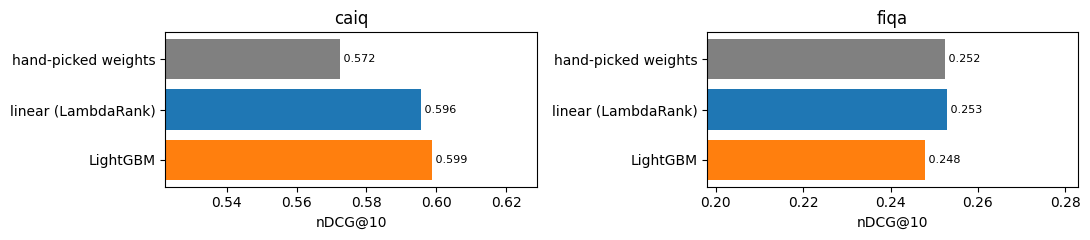

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 2.5))
for ax, ds in zip(axes, DATASETS):
    bars = {"hand-picked weights": np.take_along_axis(lexical(ds), LEX_TOP[ds.name], 1),
            "linear (LambdaRank)": LTR["linear"][ds.name], "LightGBM": LTR["lightgbm"][ds.name]}
    v = [np.mean(list(lab.evaluate_top(ds, LEX_TOP[ds.name], s).values())) for s in bars.values()]
    ax.barh(list(bars), v, color=["grey", "C0", "C1"])
    for k, x in enumerate(v):
        ax.text(x, k, f" {x:.3f}", va="center", fontsize=8)
    ax.set_xlim(min(v) - 0.05, max(v) + 0.03)
    ax.invert_yaxis()
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10")
fig.tight_layout()

In [27]:
def fit_all(ds, x):
    """Mean nDCG@10 of the linear score trained on every question (in-sample: it only compares features)."""
    return np.mean(list(lab.evaluate_top(ds, LEX_TOP[ds.name], x @ lab.lambdarank(x, Y[ds.name], lab.ideal_dcg(ds))).values()))

for ds in DATASETS:
    w = lab.lambdarank(X[ds.name], Y[ds.name], lab.ideal_dcg(ds)) / SCALE[ds.name][1]  # weights on the formula's own parts
    w = w / w.max()
    print(f"{lab.NAMES[ds.name]}: score = " + " + ".join(f"{v:.2f} · {f}" for f, v in zip(FEATURES, w) if v > 1e-3))

importance, full = {}, {}
for ds in DATASETS:
    booster = lgb.train(GBM, lgb.Dataset(X[ds.name].reshape(-1, len(FEATURES)), Y[ds.name].reshape(-1), group=[50] * len(ds.qids)), 200)
    gain = booster.feature_importance("gain") / max(booster.feature_importance("gain").sum(), 1e-9)
    full[ds.name] = fit_all(ds, X[ds.name])
    for i, f in enumerate(FEATURES):
        importance[ds.name, f] = (gain[i], fit_all(ds, np.delete(X[ds.name], i, -1)))
print(f"\n{'':16s}" + "".join(f"{lab.NAMES[ds.name] + ' gain':>12s}{lab.NAMES[ds.name] + ' nDCG without':>20s}" for ds in DATASETS))
print(f"{'(all features)':16s}" + "".join(f"{'':12s}{full[ds.name]:20.3f}" for ds in DATASETS))
for f in FEATURES:
    print(f"{f:16s}" + "".join(f"{importance[ds.name, f][0]:12.0%}{importance[ds.name, f][1]:20.3f}" for ds in DATASETS))

CAIQ: score = 0.54 · bm25 body + 1.00 · bm25 title + 0.05 · phrase title


FiQA: score = 1.00 · bm25 body + 0.06 · phrase body



                   CAIQ gain   CAIQ nDCG without   FiQA gain   FiQA nDCG without
(all features)                             0.596                           0.253
bm25 body                23%               0.547         85%               0.204
bm25 title               72%               0.515          0%               0.253
phrase body               2%               0.596         15%               0.246
phrase title              3%               0.596          0%               0.253


                        CAIQ               FiQA         
matching words         0.016              0.079         
+ stopwords            0.053 (+0.037)     0.106 (+0.028)
tf-idf                 0.030 (-0.023)     0.024 (-0.083)
bm25                   0.224 (+0.194)     0.223 (+0.199)
+ stemming             0.259 (+0.036)     0.238 (+0.016)
+ title                0.549 (+0.290)     0.238 (+0.000)
+ synonyms             0.561 (+0.012)     0.246 (+0.008)
saturated              0.567 (+0.006)     0.246 (+0.000)
+ phrase               0.572 (+0.005)     0.252 (+0.006)
learning to rank       0.596 (+0.023)     0.253 (+0.000)


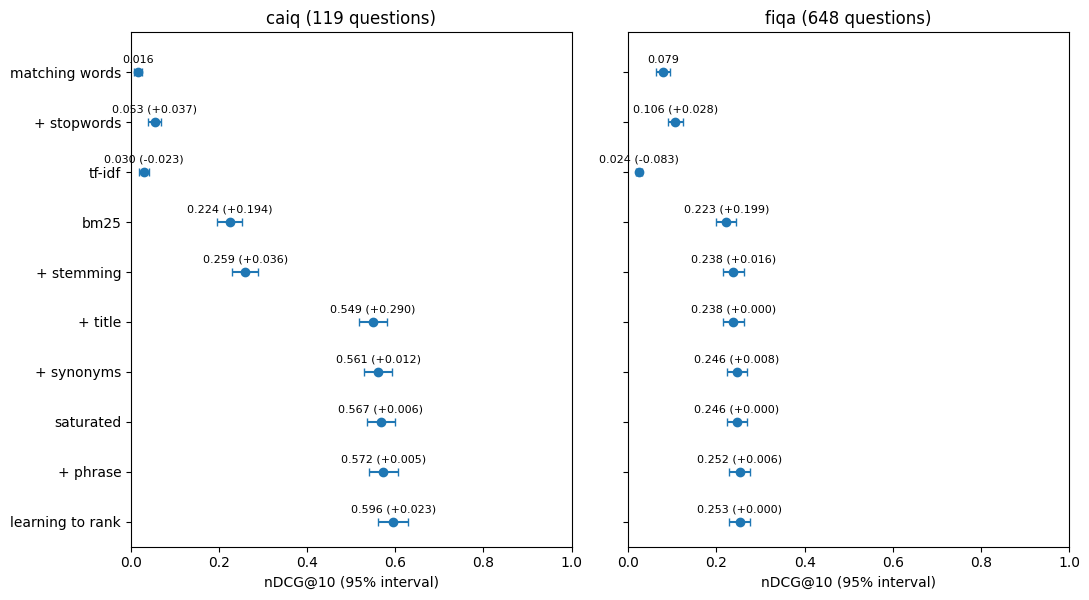

In [28]:
for ds in DATASETS:
    runs[ds.name]["learning to rank"] = lab.evaluate_top(ds, LEX_TOP[ds.name], LTR["linear"][ds.name])
lab.plot_progress(runs);

In [29]:
gain = {q: runs["caiq"]["learning to rank"][q] - runs["caiq"]["+ phrase"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
lab.show(caiq, example, {"+ phrase": lexical(caiq), "learning to rank": lab.expand(caiq, LEX_TOP["caiq"], LTR["linear"]["caiq"])})

Question  For Fimil: Is a reliable time source being used across all relevant systems?

+ phrase · nDCG@10 0.387 · 1 of the top 5 relevant
  1  ·  Yes. Incident Response Plan defines customer notification proced…
  2  ✓  Present SpA — LOG-06.1: Is a reliable time source being used acr…
  3  ·  Octopus Deploy — TVM-01.1: Do you have anti-malware programs tha…
  4  ·  Octopus Deploy — IVS-12.3: Are policies and procedures establish…
  5  ·  Fimil — TVM-05.1: Are processes to identify updates for applicat…

learning to rank · nDCG@10 0.818 · 1 of the top 5 relevant
  1  ✓  Present SpA — LOG-06.1: Is a reliable time source being used acr…
  2  ·  Yes. Incident Response Plan defines customer notification proced…
  3  ·  Octopus Deploy — TVM-02.5: Do you have a capability to patch vul…
  4  ·  Octopus Deploy — TVM-01.1: Do you have anti-malware programs tha…
  5  ·  Realigned Technologies — TVM-02.5: Do you have a capability to p…



<br><br>

## 14. Vector search

Term-based lexical search is limited to matching shared vocabulary between the question and the document, and a synonym list only covers a few known cases of vocabulary mismatch. We can use neural networks to *embed* the question and each document in a vector space, so that texts with similar meaning are close even with no shared terms, and score a document by the *cosine similarity* of its vector and the question's,

$$\cos(q, d) = \frac{\mathbf{q} \cdot \mathbf{d}}{\lVert \mathbf{q} \rVert \, \lVert \mathbf{d} \rVert},$$

where $\mathbf{q}$ and $\mathbf{d}$ are the two embedding vectors; it lies between −1 and 1.

Our embedding model reads the whole document, up to 8,192 tokens (the tokens from the model's tokenizer, not terms), so the vector of a long document describes all of it. The documents in both datasets are fairly short passages.

Our saturated lexical score from section 11 is bounded to 0-1, which enables us to combine both scores in a weighted sum. An alternative for combining unbounded scores is *reciprocal rank fusion (RRF)*. This can be superior in some cases, but we have generally found it to underperform a weighted sum of normalized scores. We combine the two as

$$s(q, d) = 4 \max\left(0,\ \cos(q, d) - 0.05\right) + s'(q, d),$$

where $s'(q, d)$ is the lexical score with phrases from section 12; the weight 4 and the offset 0.05 were chosen on these questions.

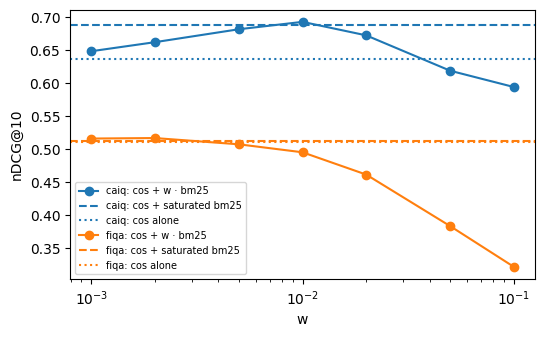

In [30]:
VEC = {ds.name: lab.vectors(ds) for ds in DATASETS}
COS = {name: q @ d.T for name, (d, q) in VEC.items()}
dense = {ds.name: lab.evaluate(ds, COS[ds.name]) for ds in DATASETS}

def naive(ds, w):
    return COS[ds.name] + w * (BODY[ds.name] + TITLE[ds.name])

def hybrid(ds):
    return 4 * np.maximum(0, COS[ds.name] - 0.05) + lexical(ds)

weights = (0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    curve = [np.mean(list(lab.evaluate(ds, naive(ds, w)).values())) for w in weights]
    ax.plot(weights, curve, marker="o", label=f"{ds.name}: cos + w · bm25")
    color = ax.lines[-1].get_color()
    ax.axhline(np.mean(list(lab.evaluate(ds, hybrid(ds)).values())), ls="--", color=color, label=f"{ds.name}: cos + saturated bm25")
    ax.axhline(np.mean(list(dense[ds.name].values())), ls=":", color=color, label=f"{ds.name}: cos alone")
ax.set_xscale("log")
ax.set_xlabel("w")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=7);

                        CAIQ               FiQA         
matching words         0.016              0.079         
+ stopwords            0.053 (+0.037)     0.106 (+0.028)
tf-idf                 0.030 (-0.023)     0.024 (-0.083)
bm25                   0.224 (+0.194)     0.223 (+0.199)
+ stemming             0.259 (+0.036)     0.238 (+0.016)
+ title                0.549 (+0.290)     0.238 (+0.000)
+ synonyms             0.561 (+0.012)     0.246 (+0.008)
saturated              0.567 (+0.006)     0.246 (+0.000)
+ phrase               0.572 (+0.005)     0.252 (+0.006)
learning to rank       0.596 (+0.023)     0.253 (+0.000)
+ dense                0.688 (+0.092)     0.512 (+0.259)


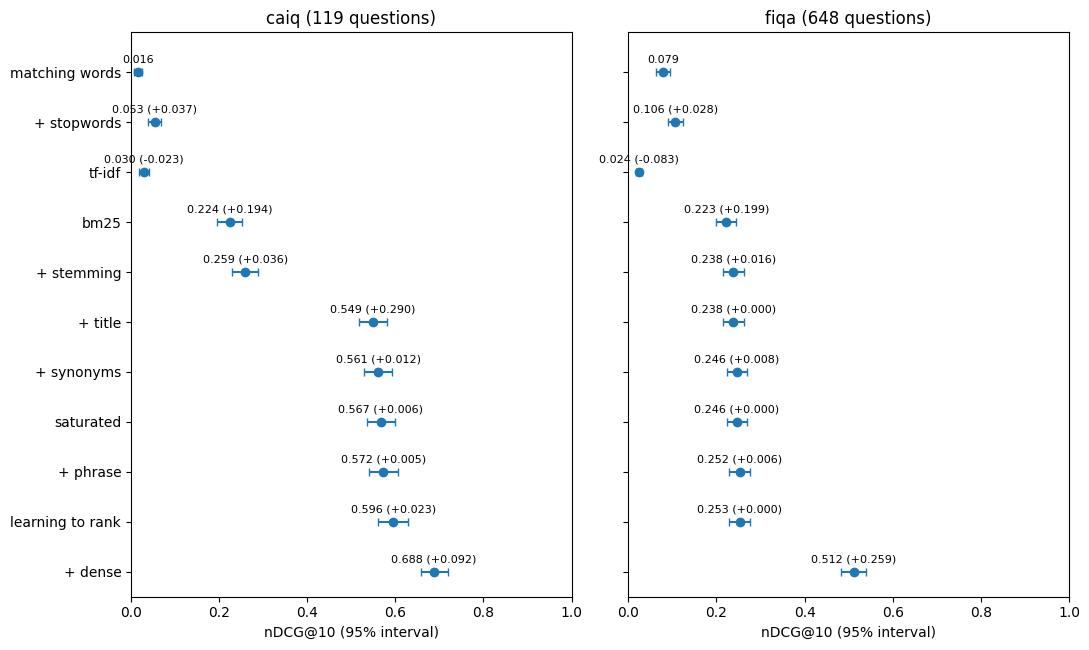

In [31]:
for ds in DATASETS:
    runs[ds.name]["+ dense"] = lab.evaluate(ds, hybrid(ds))
lab.plot_progress(runs);

In [32]:
gain = {q: runs["fiqa"]["+ dense"][q] - runs["fiqa"]["+ phrase"][q] for q in fiqa.qids}
example = max(gain, key=gain.get)
lab.show(fiqa, example, {"+ phrase": lexical(fiqa), "+ dense": hybrid(fiqa)})

Question  Can I send a money order from USPS as a business?

+ phrase · nDCG@10 0.000 · none of the top 5 relevant
  1  ·  On your end of the deal, the biggest risk is probably counterfei…
  2  ·  "> ""So I'll either stop shipping prescriptions or switch to Fed…
  3  ·  Not sure why USPS wouldn't put the screws to stamps.com. Stamps…
  4  ·  "A money order is basically a pre-paid check. The physical cash…
  5  ·  The net benefit to the US economy for the DoD is likely positive…

+ dense · nDCG@10 1.000 · 1 of the top 5 relevant
  1  ✓  Sure you can. You can fill in whatever you want in the From sect…
  2  ·  "A money order is basically a pre-paid check. The physical cash…
  3  ·  On your end of the deal, the biggest risk is probably counterfei…
  4  ·  I assume you kept the receipt for your money order, in which cas…
  5  ·  The US Postal Service to my recollection recommends only mailing…



<br><br>

## 15. Binarized embeddings

A float32 vector of 1,024 dimensions takes 4 KB per document, and at production scale, both memory and search time matter. To optimize for storage and compute constraints, we lower the precision of each document vector all the way to binary, using a sign function, resulting in a 32x reduction in storage. Subtracting the mean vector first (*centering*) keeps more information in the signs. We can still keep the queries in full precision and score a float query against binary documents, to keep most of the quality,

$$\mathbf{b}(d) = \mathrm{sign}(\mathbf{d} - \boldsymbol{\mu}), \qquad s(q, d) = \frac{(\mathbf{q} - \boldsymbol{\mu}) \cdot \mathbf{b}(d)}{\sqrt{D}},$$

where $\boldsymbol{\mu}$ is the mean document vector, $D = 1024$ the number of dimensions, and $\mathbf{b}(d)$ holds one bit per dimension, $+1$ or $-1$. The first stage now takes the top 100 from the binary vector similarity score and the top 100 from the lexical score, and scores these candidates with both.

In [33]:
def signs(x):
    return np.where(x >= 0, 1, -1).astype(np.float32)

BIN, CENTERED, ASYM = {}, {}, {}
for ds in DATASETS:
    d, q = VEC[ds.name]
    mean = d.mean(0)
    BIN[ds.name] = signs(q) @ signs(d).T
    CENTERED[ds.name] = signs(q - mean) @ signs(d - mean).T
    ASYM[ds.name] = (q - mean) @ signs(d - mean).T / np.sqrt(d.shape[1])  # the question stays float; documents are bits

print(f"{'document vectors':18s}{'float32':>10s}{'bits':>10s}")
for ds in DATASETS:
    d, _ = VEC[ds.name]
    print(f"{lab.NAMES[ds.name]:18s}{d.nbytes / 1e6:7.1f} MB{np.packbits(d >= 0, axis=1).nbytes / 1e6:7.2f} MB")
print(f"\n{'nDCG@10':18s}{'float':>7s}{'bits':>7s}{'centered bits':>16s}{'float question × centered bits':>33s}")
for ds in DATASETS:
    print(f"{lab.NAMES[ds.name]:18s}{np.mean(list(dense[ds.name].values())):7.3f}"
          f"{np.mean(list(lab.evaluate(ds, BIN[ds.name]).values())):7.3f}"
          f"{np.mean(list(lab.evaluate(ds, CENTERED[ds.name]).values())):16.3f}"
          f"{np.mean(list(lab.evaluate(ds, ASYM[ds.name]).values())):33.3f}")

document vectors     float32      bits
CAIQ                  2.6 MB   0.08 MB
FiQA                237.2 MB   7.41 MB

nDCG@10             float   bits   centered bits   float question × centered bits
CAIQ                0.636  0.598           0.608                            0.618


FiQA                0.511  0.483           0.485                            0.503


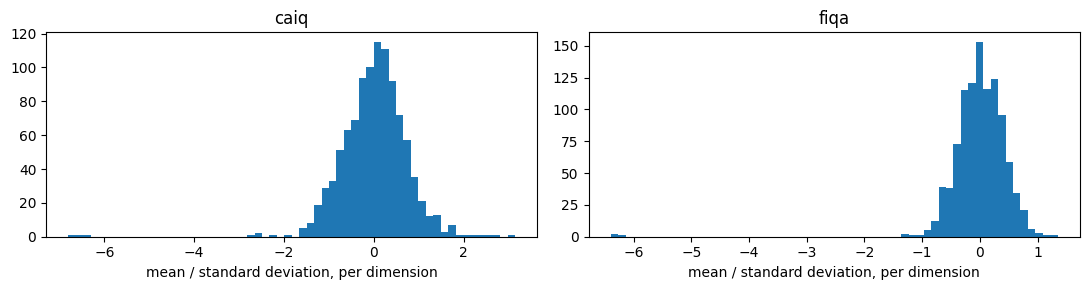

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, ds in zip(axes, DATASETS):
    d, _ = VEC[ds.name]
    ax.hist(d.mean(0) / d.std(0), bins=60)
    ax.set_title(ds.name)
    ax.set_xlabel("mean / standard deviation, per dimension")
fig.tight_layout()

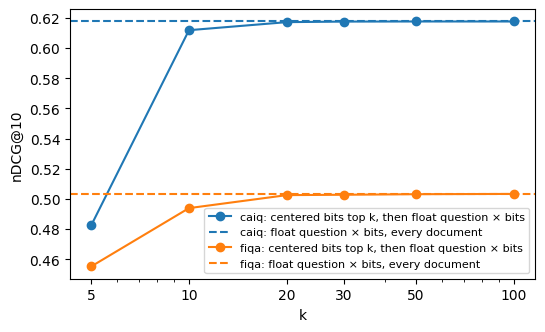

In [35]:
windows = (5, 10, 20, 30, 50, 100)
fig, ax = plt.subplots(figsize=(6, 3.5))
for ds in DATASETS:
    top = lab.topk(ds, CENTERED[ds.name], max(windows))  # the bits' top 100, once; each window is a prefix of it
    asym = np.take_along_axis(ASYM[ds.name], top, 1)
    curve = [np.mean(list(lab.evaluate_top(ds, top[:, :k], asym[:, :k]).values())) for k in windows]
    ax.plot(windows, curve, marker="o", label=f"{ds.name}: centered bits top k, then float question × bits")
    ax.axhline(np.mean(list(lab.evaluate(ds, ASYM[ds.name]).values())), ls="--", color=ax.lines[-1].get_color(),
               label=f"{ds.name}: float question × bits, every document")
ax.set_xscale("log")
ax.set_xticks(windows, windows)
ax.set_xlabel("k")
ax.set_ylabel("nDCG@10")
ax.legend(fontsize=8);

                          CAIQ               FiQA         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.504 (-0.008)


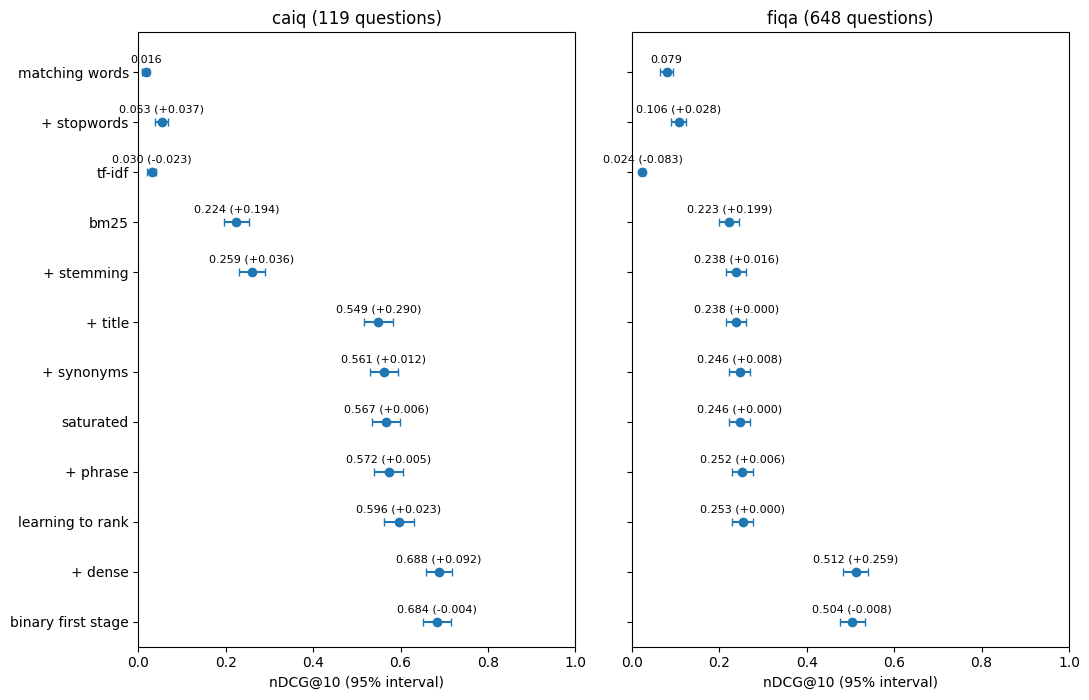

In [36]:
def hybrid_bits(ds):
    return 4 * np.maximum(0, ASYM[ds.name]) + lexical(ds)

CAND = {ds.name: lab.candidates(ds, [CENTERED[ds.name], BODY[ds.name] + TITLE[ds.name]], 100) for ds in DATASETS}
for ds in DATASETS:
    runs[ds.name]["binary first stage"] = lab.evaluate(ds, np.where(CAND[ds.name], hybrid_bits(ds), -np.inf))
lab.plot_progress(runs);

<br><br>

## 16. A vector index

Every vector search so far compared the question with every document. That scan is exact, and its cost grows with the number of documents. An *inverted file* (IVF) index does less work. It clusters the document vectors with k-means and keeps one list of documents per cluster, so a question only needs to scan the lists whose centroids are closest to it. Document $d$ goes into the list of its nearest centroid,

$$\ell(d) = \arg\max_{j} \ \mathbf{c}_j \cdot \mathbf{d},$$

where $\mathbf{c}_1, \dots, \mathbf{c}_L$ are the $L$ unit-length centroids, and a question $q$ scans the $p$ lists with the largest $\mathbf{c}_j \cdot \mathbf{q}$, ranking their documents by cosine as before. The trade is the share of documents scanned: a smaller share buys speed and costs recall, since a relevant document in a list that is not probed is never scored.

Unlike the keyword index of section 3, which finds every document that contains a term, this index changes the results. So we measure it like every other step, with recall@100 against the exact top 100 and with nDCG@10.

We cluster FiQA's documents into $L = 1{,}024$ lists, about $4\sqrt{N}$ for $N$ documents, with *spherical* k-means: every round renormalizes the centroids to unit length, so a document's nearest centroid is the one with the highest cosine. The starting centroids come from k-means++, which picks each new start at random, with a probability proportional to its squared distance to the nearest start so far. The lists are built from the documents alone; the questions only measure them. Each list's vectors are stored next to each other, so scanning a list is one matrix–vector product. We compare with faiss's `IndexIVFFlat` with the same number of lists, and time one question at a time on one CPU thread.

In [37]:
def unit(x):
    return x / np.maximum(np.linalg.norm(x, axis=-1, keepdims=True), 1e-12)

def kmeans(X, n_lists, rounds=10, seed=0):
    """Spherical k-means: n_lists unit centroids. k-means++ picks the starts, each new one likely far from those before."""
    rng = np.random.default_rng(seed)
    C = [X[rng.integers(len(X))]]
    far = 2 - 2 * (X @ C[0])  # each vector's squared distance to its nearest start
    for _ in range(n_lists - 1):
        p = np.maximum(far, 0)
        C.append(X[rng.choice(len(X), p=p / p.sum())])
        far = np.minimum(far, 2 - 2 * (X @ C[-1]))
    C = np.array(C)
    for _ in range(rounds):
        nearest = np.argmax(X @ C.T, 1)
        sums = np.zeros_like(C)
        np.add.at(sums, nearest, X)
        C = np.where(np.bincount(nearest, minlength=n_lists)[:, None] > 0, unit(sums), C)  # an empty list keeps its centroid
    return C

class IVF:
    """The documents in lists, one per centroid; each list's vectors sit next to each other in X."""
    def __init__(self, D, n_lists):
        self.C = kmeans(D, n_lists)
        nearest = np.argmax(D @ self.C.T, 1)
        self.ids = np.argsort(nearest, kind="stable")  # the document at each position of X
        self.X = D[self.ids]
        self.start = np.concatenate([[0], np.cumsum(np.bincount(nearest, minlength=n_lists))])

    def search(self, q, probe, k=100):
        """The top k by cosine among the documents in the probe lists whose centroids are closest to q."""
        lists = np.argpartition(-(self.C @ q), probe - 1)[:probe]
        spans = [(self.start[j], self.start[j + 1]) for j in lists]
        scores = np.concatenate([self.X[a:b] @ q for a, b in spans])
        where = np.concatenate([np.arange(a, b) for a, b in spans])
        best = np.argpartition(-scores, min(k, len(scores)) - 1)[:k]
        return self.ids[where[best]], scores[best]

    def scanned(self, q, probe):
        lists = np.argpartition(-(self.C @ q), probe - 1)[:probe]
        return (self.start[lists + 1] - self.start[lists]).sum() / len(self.X)

In [38]:
import time
import faiss
from threadpoolctl import threadpool_limits

faiss.omp_set_num_threads(1)

def measure(ds, search):
    """recall@100 against the exact top 100, nDCG@10, and ms per question: one question at a time, on one thread."""
    _, Q = VEC[ds.name]
    with threadpool_limits(1):
        for x in Q[:20]:
            search(x)  # warm up
        passes = []
        for _ in range(3):  # the fastest of three passes, the least disturbed by other work
            t0 = time.perf_counter()
            found = [search(x) for x in Q]
            passes.append(1000 * (time.perf_counter() - t0) / len(Q))
        ms = min(passes)
    exact = np.argpartition(-COS[ds.name], 99, axis=1)[:, :100]
    scores = np.full(COS[ds.name].shape, -np.inf, dtype=np.float32)
    for r, (rows, s) in enumerate(found):
        scores[r, rows[rows >= 0]] = s[rows >= 0]  # faiss pads a short list of hits with -1
    recall = np.mean([np.isin(e, rows).mean() for e, (rows, _) in zip(exact, found)])
    return recall, np.mean(list(lab.evaluate(ds, scores).values())), ms

def exact_search(D):
    def search(q):
        s = D @ q
        top = np.argpartition(-s, 99)[:100]
        return top, s[top]
    return search

def faiss_search(index, probe):
    params = faiss.SearchParametersIVF(nprobe=probe)
    def search(q):
        s, rows = index.search(q[None], 100, params=params)
        return rows[0], s[0]
    return search

D, Q = VEC["fiqa"]
L, PROBES = 1024, (16, 46, 82)
with threadpool_limits(1):
    t0 = time.perf_counter()
    ivf = IVF(D, L)
    built = time.perf_counter() - t0
    t0 = time.perf_counter()
    quantizer = faiss.IndexFlatIP(D.shape[1])
    faiss_ivf = faiss.IndexIVFFlat(quantizer, D.shape[1], L, faiss.METRIC_INNER_PRODUCT)
    faiss_ivf.train(D)
    faiss_ivf.add(D)
    faiss_built = time.perf_counter() - t0
sizes = np.array([faiss_ivf.invlists.list_size(j) for j in range(L)])

TABLE = {"exact": (1.0, *measure(fiqa, exact_search(D)))}
for p in PROBES:
    TABLE[f"ours, probe {p}"] = (np.mean([ivf.scanned(x, p) for x in Q]), *measure(fiqa, lambda x, p=p: ivf.search(x, p)))
for p in PROBES:
    share = sizes[quantizer.search(Q, p)[1]].sum(1).mean() / len(D)
    TABLE[f"faiss IVFFlat, nprobe {p}"] = (share, *measure(fiqa, faiss_search(faiss_ivf, p)))
print(f"FiQA, {len(D):,} documents, {L:,} lists, {len(Q)} questions, one thread\n")
print(f"{'':26s}{'scanned':>8s}{'recall@100':>12s}{'nDCG@10':>9s}{'ms per question':>17s}")
for name, (share, recall, ndcg, ms) in TABLE.items():
    print(f"{name:26s}{share:8.1%}{recall:12.3f}{ndcg:9.3f}{ms:17.2f}")
print(f"\nbuild, one thread: ours {built:.0f} s (k-means++ and 10 rounds) · faiss {faiss_built:.0f} s")

FiQA, 57,912 documents, 1,024 lists, 648 questions, one thread

                           scanned  recall@100  nDCG@10  ms per question
exact                       100.0%       1.000    0.511             9.51
ours, probe 16                2.0%       0.845    0.487             0.31
ours, probe 46                5.4%       0.945    0.504             0.64
ours, probe 82                9.5%       0.973    0.507             1.40
faiss IVFFlat, nprobe 16      1.7%       0.832    0.489             0.21
faiss IVFFlat, nprobe 46      4.9%       0.940    0.507             0.47
faiss IVFFlat, nprobe 82      8.6%       0.969    0.508             0.80

build, one thread: ours 34 s (k-means++ and 10 rounds) · faiss 11 s


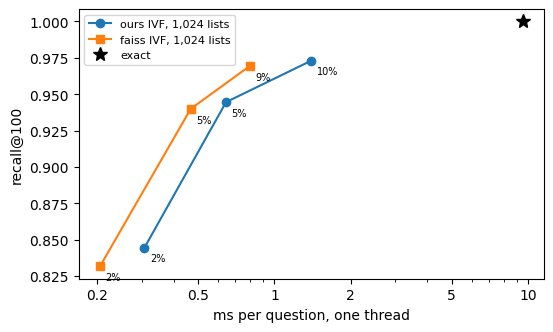

In [39]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, marker in (("ours", "o"), ("faiss", "s")):
    rows = [v for k, v in TABLE.items() if k.startswith(name)]
    ax.plot([v[3] for v in rows], [v[1] for v in rows], marker=marker, label=f"{name} IVF, {L:,} lists")
    for share, recall, _, ms in rows:
        ax.annotate(f"{share:.0%}", (ms, recall), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax.plot(TABLE["exact"][3], 1.0, "k*", markersize=10, label="exact")
ax.set_xscale("log")
ax.set_xticks((0.2, 0.5, 1, 2, 5, 10), ("0.2", "0.5", "1", "2", "5", "10"))
ax.set_xlabel("ms per question, one thread")
ax.set_ylabel("recall@100")
ax.legend(fontsize=8);

In [40]:
D, Q = VEC["caiq"]
small = IVF(D, 128)  # about 4√N lists, as for FiQA
p = 6
recall, ndcg, ms = measure(caiq, lambda x: small.search(x, p))
_, exact_ndcg, exact_ms = measure(caiq, exact_search(D))
print(f"CAIQ, {len(D)} documents: exact {exact_ms:.3f} ms per question, nDCG@10 {exact_ndcg:.3f} · IVF 128 lists, probe {p} "
      f"({np.mean([small.scanned(x, p) for x in Q]):.0%} scanned) {ms:.3f} ms, nDCG@10 {ndcg:.3f}")

CAIQ, 644 documents: exact 0.040 ms per question, nDCG@10 0.636 · IVF 128 lists, probe 6 (6% scanned) 0.034 ms, nDCG@10 0.577


At FiQA's size, scanning 5.4% of the documents is 15 times faster than the exact scan on one thread (0.64 ms against 9.51 ms per question), keeps 94.5% of the true top 100, and costs 0.007 nDCG@10 (0.504 against 0.511); at 9.5% scanned the cost falls to 0.004. Our index is a faithful IVF: at the same probes its recall matches that of faiss's `IndexIVFFlat`, and it runs 1.4 to 1.8 times slower, the price of Python. The price stays small because the Python loop runs once per list, never once per document, and each list is one array operation. In Python, keep loops short and push the arithmetic into array operations. On CAIQ's 644 documents an index does not pay off: the exact scan is about as fast (0.040 against 0.034 ms per question), and the index, scanning 6%, loses 0.06 nDCG@10 (0.577 against 0.636).

Several refinements did not help on these documents: spilling each document into its second-nearest list too, balancing the list sizes, choosing the number of probes per question, and scanning int8 or binary codes before the float vectors. In memory, a graph index such as HNSW gets more recall per millisecond than IVF; IVF's strengths are elsewhere, on disk, under filters, and with updates.

<br><br>

## 17. Late interaction

In a simple dense embedding, a single vector has to summarize a whole passage of text. Late interaction (ColBERT) keeps one vector per token instead, and scores a document by matching each question token to its best document token (*MaxSim*), summed over the question,

$$\mathrm{MaxSim}(q, d) = \sum_{i=1}^{\lvert q \rvert} \max_{1 \le j \le \lvert d \rvert} \mathbf{q}_i \cdot \mathbf{d}_j,$$

where $\mathbf{q}_i$ is the vector of the question's $i$-th token, $\mathbf{d}_j$ the vector of the document's $j$-th token, and $\lvert q \rvert$ and $\lvert d \rvert$ their numbers of tokens.

In practice, computing MaxSim over the whole matching result set is not practical. To simulate this *two-stage* ranking algorithm, our late interaction reranks only the first stage's top 30. We use Perplexity's pplx-embed-v2-late-0.6b and mix its score with the weighted sum score from the previous stage,

$$s(q, d) = \mathrm{minmax}\left(s_1(q, d)\right) + \lambda \, \mathrm{minmax}\left(\mathrm{MaxSim}(q, d)\right),$$

where $s_1$ is the first stage's score, $\mathrm{minmax}$ rescales a question's 30 candidate scores to the range 0 to 1, and $\lambda$ is read off the curves below.

In [37]:
FIRST = {ds.name: np.where(CAND[ds.name], hybrid_bits(ds), -np.inf) for ds in DATASETS}
TOP30 = {ds.name: lab.topk(ds, FIRST[ds.name], 30) for ds in DATASETS}  # late interaction reranks these
TOP20 = {name: top[:, :20] for name, top in TOP30.items()}  # and the cross-encoder in section 18 these

def at(ds, scores, top):
    return np.take_along_axis(scores, top[ds.name], 1)

def minmax(x):
    lo, hi = x.min(1, keepdims=True), x.max(1, keepdims=True)
    return (x - lo) / np.maximum(hi - lo, 1e-9)

TOK = {ds.name: lab.late_tokens(ds, ENCODE_ON_GPU) for ds in DATASETS}
d_bytes = 1024 * 2
VECTORS = {ds.name: np.diff(TOK[ds.name].start).mean() for ds in DATASETS}  # pplx v2-late vectors per document
BYTES = {}
for ds in DATASETS:
    n = VECTORS[ds.name]
    BYTES[ds.name] = {"dense (one vector), float16": d_bytes, "dense (one vector), bits": d_bytes // 16,
                      "pplx v2-late, float16": n * 256, "pplx v2-late, int8": n * 128, "pplx v2-late, bits": n * 16}
print(f"{'bytes per document':30s}" + "".join(f"{lab.NAMES[ds.name]:>9s}" for ds in DATASETS))
for form in BYTES["caiq"]:
    print(f"{form:30s}" + "".join(f"{BYTES[ds.name][form]:9,.0f}" for ds in DATASETS))
print("\npplx v2-late vectors (128 numbers each) per document:  "
      + " · ".join(f"{lab.NAMES[ds.name]} {VECTORS[ds.name]:.0f}" for ds in DATASETS))

bytes per document                 CAIQ     FiQA
dense (one vector), float16       2,048    2,048
dense (one vector), bits            128      128
pplx v2-late, float16            27,379   41,622
pplx v2-late, int8               13,689   20,811
pplx v2-late, bits                1,711    2,601

pplx v2-late vectors (128 numbers each) per document:  CAIQ 107 · FiQA 163


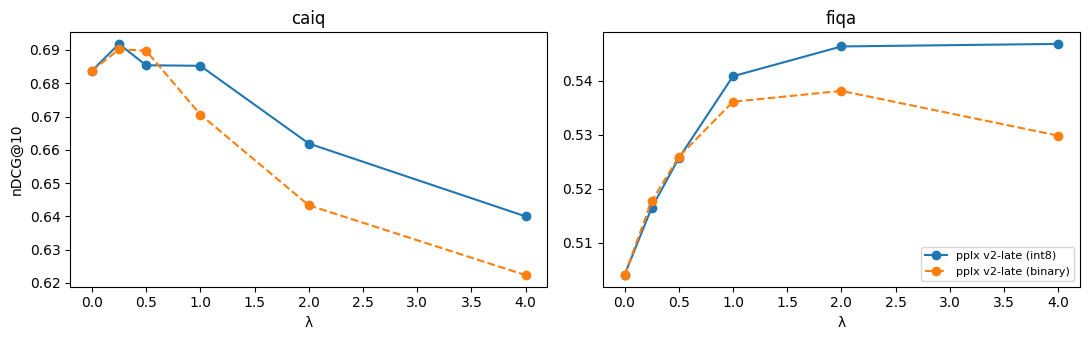

In [38]:
LATE = {form: {ds.name: lab.maxsim(ds, TOK[ds.name], TOP30[ds.name], binary=form == "binary") for ds in DATASETS}
        for form in ("int8", "binary")}

def fused(ds, scores, lam):
    return minmax(at(ds, FIRST[ds.name], TOP30)) + lam * minmax(scores)

lams = (0, 0.25, 0.5, 1, 2, 4)
CURVE = {(form, ds.name): [np.mean(list(lab.evaluate_top(ds, TOP30[ds.name], fused(ds, LATE[form][ds.name], lam)).values()))
                           for lam in lams] for form in LATE for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    for form, ls in (("int8", "-"), ("binary", "--")):
        ax.plot(lams, CURVE[form, ds.name], ls=ls, marker="o", label=f"pplx v2-late ({form})")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

In [39]:
ALONE = {ds.name: {"first stage": at(ds, FIRST[ds.name], TOP30), **{f"pplx v2-late ({form})": LATE[form][ds.name] for form in LATE}}
         for ds in DATASETS}
print(f"{'nDCG@10 of the same top 30, ordered by':40s}" + "".join(f"{lab.NAMES[ds.name]:>8s}" for ds in DATASETS))
for name in ALONE["caiq"]:
    print(f"  {name:38s}" + "".join(
        f"{np.mean(list(lab.evaluate_top(ds, TOP30[ds.name], ALONE[ds.name][name]).values())):8.3f}" for ds in DATASETS))

nDCG@10 of the same top 30, ordered by      CAIQ    FiQA
  first stage                              0.684   0.504
  pplx v2-late (int8)                      0.604   0.535
  pplx v2-late (binary)                    0.586   0.497


λ for late interaction:  CAIQ 0.25 · FiQA 2

                          CAIQ               FiQA         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.504 (-0.008)
+ late interaction       0.690 (+0.006)     0.538 (+0.034)


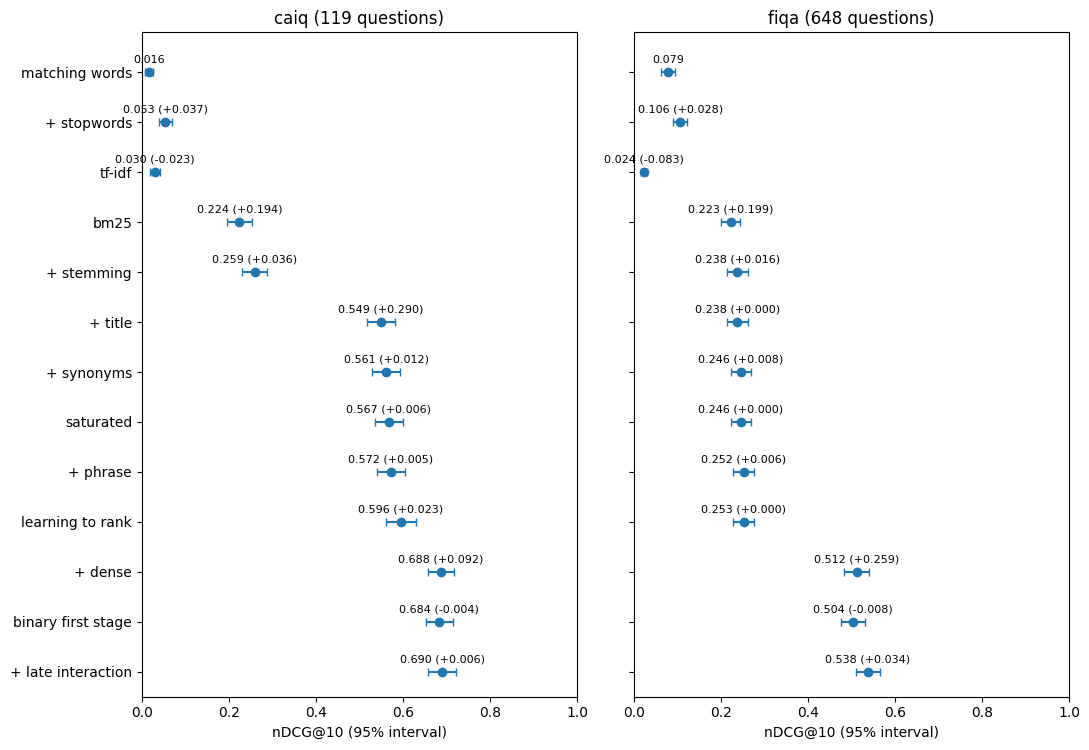

In [40]:
LAM_LATE = {ds.name: lams[int(np.argmax(CURVE["binary", ds.name]))] for ds in DATASETS}  # read off the curves above
print("λ for late interaction:  " + " · ".join(f"{lab.NAMES[name]} {lam}" for name, lam in LAM_LATE.items()) + "\n")
for ds in DATASETS:
    runs[ds.name]["+ late interaction"] = lab.evaluate_top(ds, TOP30[ds.name], fused(ds, LATE["binary"][ds.name], LAM_LATE[ds.name]))
lab.plot_progress(runs);

In [41]:
print(f"{'':8s}" + "".join(f"{lab.NAMES[ds.name] + ' best nDCG@10':>19s}{'bytes per document':>21s}" for ds in DATASETS))
for form in LATE:
    cells = []
    for ds in DATASETS:
        n = np.diff(TOK[ds.name].start).mean()
        size = {"int8": n * 128, "binary": n * 16}
        cells.append(f"{max(CURVE[form, ds.name]):19.3f}{size[form]:21,.0f}")
    print(f"{form:8s}" + "".join(cells))

          CAIQ best nDCG@10   bytes per document  FiQA best nDCG@10   bytes per document
int8                  0.692               13,689              0.547               20,811
binary                0.690                1,711              0.538                2,601


<br><br>

## 18. Cross-encoder

Both dense and late interaction embedding models encode the question and the document separately (a *bi-encoder*) ahead of time, so the document vectors can be computed offline and only the similarity computation is required at query time. A cross-encoder reads the question and the document tokens together at query time and outputs a relevance score. This section is for learning only: the graded search has no reranker.

The cross-encoder is the most accurate ranking method but also the most expensive one, since nothing can be precomputed. It is commonly used in a *two-stage* design: a cheap first stage for recall followed by an expensive reranker for precision. Qwen3-Reranker-4B, a cross-encoder, runs on your GPU; it scores each of the notebook's top 20 documents for each question, and the scores are kept so a repeat is instant:

Output()

Output()

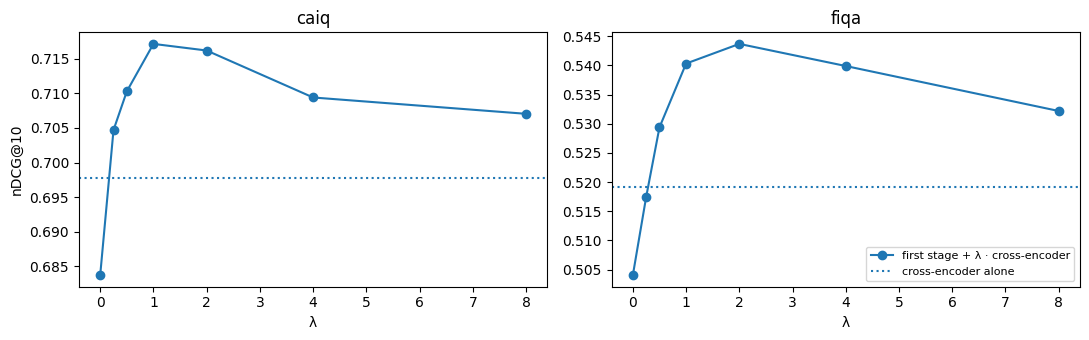

In [42]:
CE = {ds.name: lab.rerank_rows(ds, TOP20[ds.name]) for ds in DATASETS}

def reranked(ds, lam):
    return minmax(at(ds, FIRST[ds.name], TOP20)) + lam * minmax(CE[ds.name])

lams = (0, 0.25, 0.5, 1, 2, 4, 8)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, DATASETS):
    ax.plot(lams, [np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam)).values())) for lam in lams],
            marker="o", label="first stage + λ · cross-encoder")
    ax.axhline(np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], CE[ds.name]).values())), ls=":",
               color=ax.lines[-1].get_color(), label="cross-encoder alone")
    ax.set_title(ds.name)
    ax.set_xlabel("λ")
axes[0].set_ylabel("nDCG@10")
axes[1].legend(fontsize=8)
fig.tight_layout()

λ for the cross-encoder:  CAIQ 1 · FiQA 2

                          CAIQ               FiQA         
matching words           0.016              0.079         
+ stopwords              0.053 (+0.037)     0.106 (+0.028)
tf-idf                   0.030 (-0.023)     0.024 (-0.083)
bm25                     0.224 (+0.194)     0.223 (+0.199)
+ stemming               0.259 (+0.036)     0.238 (+0.016)
+ title                  0.549 (+0.290)     0.238 (+0.000)
+ synonyms               0.561 (+0.012)     0.246 (+0.008)
saturated                0.567 (+0.006)     0.246 (+0.000)
+ phrase                 0.572 (+0.005)     0.252 (+0.006)
learning to rank         0.596 (+0.023)     0.253 (+0.000)
+ dense                  0.688 (+0.092)     0.512 (+0.259)
binary first stage       0.684 (-0.004)     0.504 (-0.008)
+ late interaction       0.690 (+0.006)     0.538 (+0.034)
+ cross-encoder          0.717 (+0.027)     0.544 (+0.006)


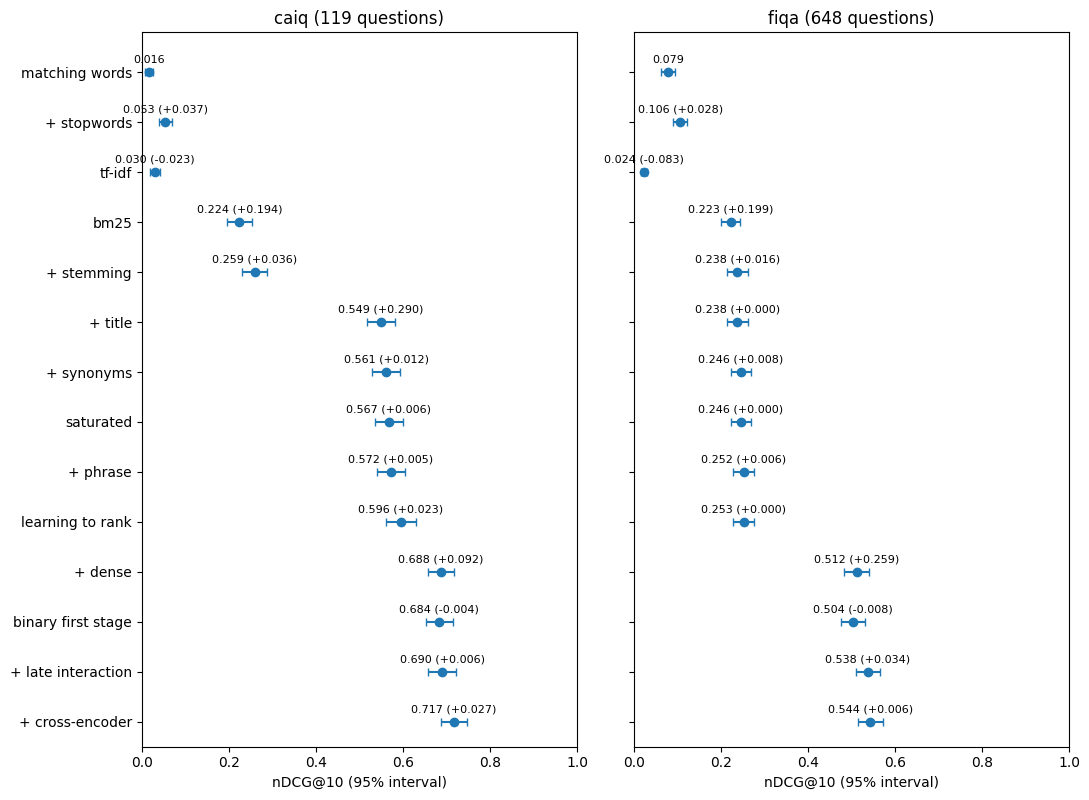

In [43]:
LAM_CE = {ds.name: max(lams, key=lambda lam: np.mean(list(lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, lam)).values())))
          for ds in DATASETS}  # read off the curves above
print("λ for the cross-encoder:  " + " · ".join(f"{lab.NAMES[name]} {lam}" for name, lam in LAM_CE.items()) + "\n")
for ds in DATASETS:
    runs[ds.name]["+ cross-encoder"] = lab.evaluate_top(ds, TOP20[ds.name], reranked(ds, LAM_CE[ds.name]))
lab.plot_progress(runs);

In [44]:
gain = {q: runs["caiq"]["+ cross-encoder"][q] - runs["caiq"]["binary first stage"][q] for q in caiq.qids}
example = max(gain, key=gain.get)
lab.show(caiq, example, {"binary first stage": FIRST["caiq"],
                            "+ cross-encoder": lab.expand(caiq, TOP20["caiq"], reranked(caiq, LAM_CE["caiq"]))})

Question  For Octopus Deploy: Are audit logs reviewed on a regular basis for security events (e.g., with automated tool…

binary first stage · nDCG@10 0.567 · 2 of the top 5 relevant
  1  ·  Yes. Change Management Policy defines Emergency change type with…
  2  ·  Octopus Deploy — AIS-01.2: Do you use an automated source code a…
  3  ·  Octopus Deploy — AIS-01.5: (SaaS only) Do you review your applic…
  4  ✓  Octopus Deploy — IAM-01.1: Do you restrict, log, and monitor acc…
  5  ✓  Octopus Deploy — IAM-01.2: Do you monitor and log privileged acc…

+ cross-encoder · nDCG@10 0.905 · 4 of the top 5 relevant
  1  ✓  Octopus Deploy — IAM-01.1: Do you restrict, log, and monitor acc…
  2  ·  Octopus Deploy — AIS-01.5: (SaaS only) Do you review your applic…
  3  ✓  Octopus Deploy — IAM-01.2: Do you monitor and log privileged acc…
  4  ✓  Octopus Deploy — IVS-01.2: Is physical and logical user access t…
  5  ✓  Fimil — LOG-05.1: Are security audit logs monitored to detect un…



<br><br>

## 19. Estimating uncertainty

Every number so far is a mean over a sample of questions: 119 in CAIQ, 648 in FiQA. Another sample would give a different mean, so a small difference between two steps may be noise. The *bootstrap* resamples the questions many times and gives a 95% interval for the mean. This gives us a cheap estimate of sampling uncertainty which does not depend on a lot of assumptions. You can use it on any kind of evaluation. The bootstrap draws $B = 10{,}000$ resampled means

$$\bar{x}^{*}_{b} = \frac{1}{n} \sum_{i=1}^{n} x_{I_{b,i}}, \qquad b = 1, \dots, B,$$

where $x_i$ is question $i$'s nDCG@10, $n$ the number of questions, and each $I_{b,i}$ a question index drawn at random, with replacement, from $1, \dots, n$. The 95% interval runs from the 2.5th to the 97.5th percentile of these means.

Obviously, many kinds of uncertainty are not captured by this interval, but we recommend using a bootstrap 95% CI as a basic diagnostic when evaluating changes. If your proposed change cannot clear this interval, then it is not distinguishable from noise on the dataset. You need more data and/or a bigger improvement.

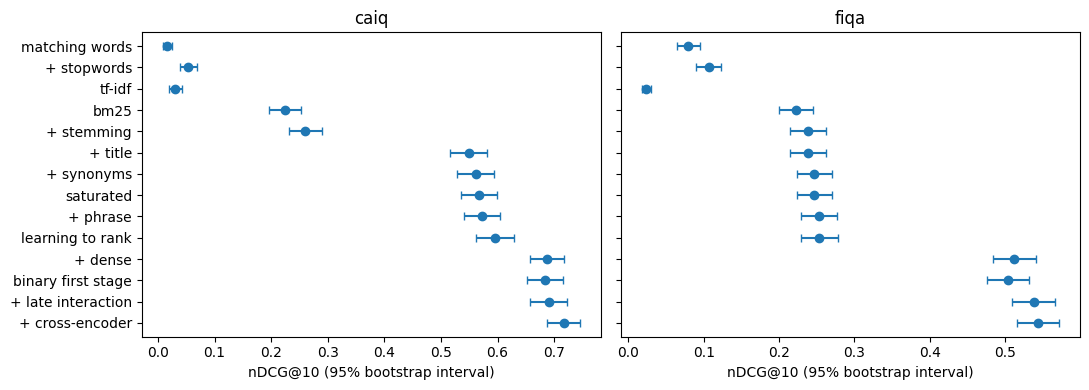

In [45]:
PER_Q = {ds.name: {step: np.array([r[q] for q in ds.qids]) for step, r in runs[ds.name].items()} for ds in DATASETS}
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, step in enumerate(steps):
        x = PER_Q[ds.name][step]
        lo, hi = lab.bootstrap(x)
        ax.errorbar(x.mean(), i, xerr=[[x.mean() - lo], [hi - x.mean()]], fmt="o", color="C0", capsize=3)
    ax.set_yticks(range(len(steps)), steps)
    ax.set_title(ds.name)
    ax.set_xlabel("nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

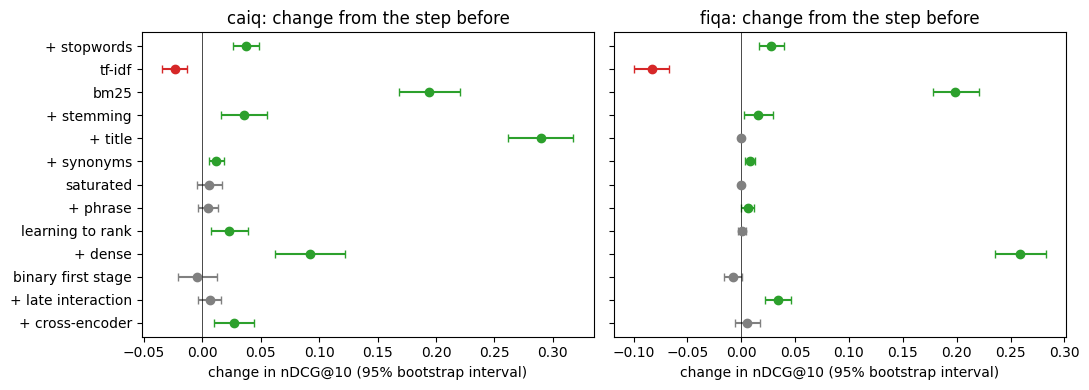

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, ds in zip(axes, DATASETS):
    steps = list(PER_Q[ds.name])
    for i, (before, step) in enumerate(zip(steps, steps[1:])):
        d = PER_Q[ds.name][step] - PER_Q[ds.name][before]  # the same questions, before and after
        lo, hi = lab.bootstrap(d)
        color = "C2" if lo > 0 else "C3" if hi < 0 else "grey"
        ax.errorbar(d.mean(), i, xerr=[[d.mean() - lo], [hi - d.mean()]], fmt="o", color=color, capsize=3)
    ax.axvline(0, color="black", lw=0.5)
    ax.set_yticks(range(len(steps) - 1), steps[1:])
    ax.set_title(f"{ds.name}: change from the step before")
    ax.set_xlabel("change in nDCG@10 (95% bootstrap interval)")
axes[0].invert_yaxis()
fig.tight_layout()

<br><br>

## 20. Leaderboard

The live leaderboard shows your search's nDCG@10 on the FiQA dev questions. The final one grades the `search/` folder you submit with `lab submit` on FiQA questions that are not in the notebook, and keeps its scores hidden until the results. Write a function that takes a single question and returns the documents in ranked order, and submit it! Connect once with `lab connect URL TOKEN`, using the URL and token from the lab page.

In [47]:
import json, re
from concurrent.futures import ThreadPoolExecutor

def embed(text):
    """The question's pplx vector, from the encoder that made the documents' vectors (on your machine)."""
    return lab.embed([text])

In [48]:
DOC_BITS = {name: (d.mean(0), signs(d - d.mean(0))) for name, (d, _) in VEC.items()}

def search(ds, query, qid=None, k=5, mask=None, rerank=True):
    """Hybrid + rerank for a single question: lexical + dense over the candidates (the top 100 by bits and the top 100 by
    BM25), then Qwen3-Reranker-4B on the top 20, mixed in with section 18's λ.
    qid hides what that question hides (its own answer); mask (one bool per document) searches only those documents;
    rerank=False stops before the reranker."""
    one = lab.single(ds, query, qid)
    keep = np.ones(len(ds.ids), dtype=bool) if mask is None else np.asarray(mask)
    only = lambda s: np.where(keep, s, -np.inf)
    body = lab.bm25(one, ds.bodies, idf_texts=ds.title_body, analyzer=ANALYZER)
    title = lab.bm25(one, ds.titles, idf_texts=ds.title_body, analyzer=ANALYZER)
    lexical = body / (kappa + body) + title / (kappa + title) + 0.2 * (0.5 * lab.phrase(one, ds.bodies, ANALYZER) + lab.phrase(one, ds.titles, ANALYZER))
    q = embed(query)
    mean, bits = DOC_BITS[ds.name]
    cand = lab.candidates(one, [only(signs(q - mean) @ bits.T), only(body + title)], min(100, len(ds.ids)))
    first = np.where(cand & keep, 4 * np.maximum(0, (q - mean) @ bits.T / np.sqrt(bits.shape[1])) + lexical, -np.inf)
    top = lab.topk(one, first, min(20, len(ds.ids)))
    top = top[:, np.isfinite(np.take_along_axis(first, top, 1))[0]]
    if not rerank or top.shape[1] < 2:
        return top[0][:k]
    fused = minmax(np.take_along_axis(first, top, 1)) + LAM_CE[ds.name] * minmax(np.array([lab.rerank_local(ds, query, top[0])]))
    return top[0][np.argsort(-fused[0])][:k]

def bm25_search(ds, query, qid=None, k=5):
    """Plain BM25 over the body."""
    one = lab.single(ds, query, qid)
    return lab.topk(one, lab.bm25(one, ds.bodies), k)[0]

def hits(ds, rows):
    return "\n".join(f"{n}. [doc:{ds.ids[i]}] {ds.titles[i]}\n   {ds.bodies[i][:300]}" for n, i in enumerate(rows, 1))

def read(ds, doc_id):
    i = ds.row.get(doc_id)
    return f"[doc:{doc_id}] {ds.titles[i]}\n{ds.bodies[i][:4000]}" if i is not None else f"no document {doc_id}"

In [49]:
for label, fn in (("bm25", bm25_search), ("hybrid + rerank", search)):
    r = lab.submit(fiqa, fn, label)
    print(f"{label}: dev nDCG@10 {r['score']:.3f} · rank {r['rank']} of {r['of']} on the live board")

bm25: nDCG@10 0.247 on the leaderboard's questions · your best 0.578 · rank 3 of 7


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

hybrid + rerank: nDCG@10 0.578 on the leaderboard's questions · your best 0.578 · rank 3 of 7


To continue in your own files instead of the notebook, edit the `search/` folder: the query (`search.py`), what Vespa holds (`feed.py`), how a question is read (`analyze.py`), `synonyms.json` and the Vespa application (`app/`). Then `lab eval search` and `lab submit search`.

<br><br>

## 21. A RAG agent from scratch

Search is usually just a capability among others, that we would like to expose to a language model. A search *agent* decides what to search for, reads the results and searches again until it can answer. `lab serve` starts a language model on your GPU, behind an OpenAI-compatible API. We evaluate the agent's answers against a Python grader using the question's relevance judgments.

In [50]:
chat = lab.chat  # the language model on your GPU

reply = chat([dict(role="user", content="In one sentence: what does BM25 score?")])
print(reply["choices"][0]["message"]["content"])
print(f"\n{reply['usage']['prompt_tokens']:,} tokens in, {reply['usage']['completion_tokens']:,} tokens out")

agent model: deepseek-v4-flash through the lab (nvidia/NVIDIA-Nemotron-3-Nano-30B-A3B-FP8 is not running here)


BM25 scores the relevance of a document to a specific search query by combining the frequency of query terms within that document, normalized by document length, and weighted by how rare those terms are across the entire corpus (inverse document frequency).

14 tokens in, 646 tokens out


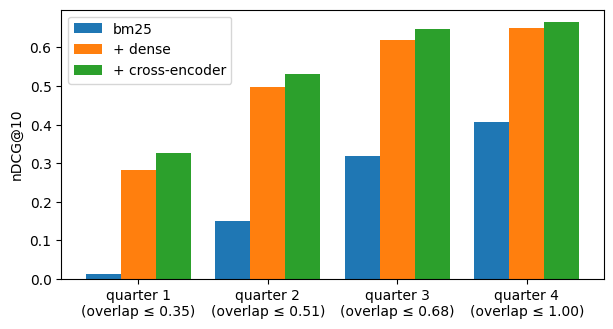

In [51]:
INDEX = lab.index(fiqa.bodies)

def overlap(ds, qid):
    """How much of the question's wording (weighted by idf) its best relevant post contains."""
    weight = {t: INDEX.idf[INDEX.vocab[t]] for t in set(lab.tokenize(ds.queries[qid])) if t in INDEX.vocab}
    total = sum(weight.values()) or 1.0
    posts = [set(lab.tokenize(ds.bodies[ds.row[d]])) for d, g in ds.qrels[qid].items() if g > 0 and d in ds.row]
    return max((sum(w for t, w in weight.items() if t in p) / total for p in posts), default=0.0)

OVERLAP = np.array([overlap(fiqa, q) for q in fiqa.qids])
quarter = np.digitize(OVERLAP, np.quantile(OVERLAP, [0.25, 0.5, 0.75]))
fig, ax = plt.subplots(figsize=(7, 3.5))
for k, step in enumerate(("bm25", "+ dense", "+ cross-encoder")):
    ax.bar(np.arange(4) + 0.27 * (k - 1), [np.mean([runs["fiqa"][step][q] for q, b in zip(fiqa.qids, quarter) if b == j])
                                            for j in range(4)], 0.27, label=step)
ax.set_xticks(range(4), [f"quarter {j + 1}\n(overlap ≤ {OVERLAP[quarter == j].max():.2f})" for j in range(4)])
ax.set_ylabel("nDCG@10")
ax.legend();

In [50]:
HARD = sorted(np.random.default_rng(0).choice([q for q, b in zip(fiqa.qids, quarter) if b == 0], 15, replace=False))
qid = HARD[0]
print(f"Question  {fiqa.queries[qid]}\n")
for name, fn in (("bm25_search", bm25_search), ("search", search)):
    lab.print_ranked(fiqa, qid, fn(fiqa, fiqa.queries[qid], qid), name)
    print()


Question  Understanding the T + 3 settlement days rule

bm25_search · none of the top 5 relevant
  1  ·  Your question is unanswerable as you haven't provided enough inf…
  2  ·  During the settlement period, the buyer transfers payment to the…
  3  ·  It's important to understand that, in general, security transact…
  4  ·  Take a look at http://en.wikipedia.org/wiki/Payment_gateway Ther…
  5  ·  Short answer: the CD can be considered as part of the down payme…



Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

search · none of the top 5 relevant
  1  ·  That is the standard set by most securities exchanges: T+3 : tra…
  2  ·  The T+3 settlement date only affects cash accounts. In a cash ac…
  3  ·  "The T+3 ""rule"" relates only to accounting and not to trading.…
  4  ·  It's important to understand that, in general, security transact…
  5  ·  "The settlement date for any trade is the date on which the sell…



In [53]:
SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If "
          "the posts do not answer the question, say so. Search with a few focused queries, read the most promising posts, "
          "and cite every post you rely on as [doc:ID].")
TOOLS = [
    dict(type="function", function=dict(name="search", description="Search the forum posts. Returns the 5 best posts with a snippet each.",
                                        parameters=dict(type="object", properties=dict(query=dict(type="string")), required=["query"]))),
    dict(type="function", function=dict(name="read", description="Read one post in full.",
                                        parameters=dict(type="object", properties=dict(doc_id=dict(type="string")), required=["doc_id"]))),
]

def agent(ds, qid, search_with, budget=2, verbose=False):
    """The model answers question qid with up to `budget` turns of tool calls, then one turn with tools off."""
    messages = [dict(role="system", content=SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, tokens = set(), 0, 0
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, TOOLS, "auto" if turn < budget else "none")
        tokens += reply["usage"]["total_tokens"]
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if verbose:
                print(f"{name}  {args.get('query', args.get('doc_id'))}")
            if name == "search":
                rows = search_with(ds, args["query"], qid)
                seen |= {ds.ids[i] for i in rows}
                searches += 1
                out = hits(ds, rows)
            else:
                out = read(ds, args["doc_id"])
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, tokens)

def rag(ds, qid, search_with):
    """Classic RAG: one search with the question itself, the top 5 in the prompt, one answer."""
    rows = search_with(ds, ds.queries[qid], qid)
    reply = chat([dict(role="system", content=SYSTEM),
                  dict(role="user", content=f"{ds.queries[qid]}\n\nSearch results:\n{hits(ds, rows)}")])
    return outcome(ds, qid, reply["choices"][0]["message"]["content"] or "", {ds.ids[i] for i in rows}, 1,
                   reply["usage"]["total_tokens"])

def outcome(ds, qid, answer, seen, searches, tokens):
    """The run's facts, checked against the question's graded posts: score is 1 when the answer cites a relevant post."""
    relevant = lambda d: ds.qrels[qid].get(d, 0) > 0
    cited = set(re.findall(r"\[doc:([^\]]+)\]", answer))
    return dict(answer=answer, searches=searches, tokens=tokens, seen_relevant=any(map(relevant, seen)),
                cited=len(cited), cited_relevant=sum(map(relevant, cited)), score=float(any(map(relevant, cited))))


In [63]:
run = agent(fiqa, qid, search, verbose=True)
print("\n" + run["answer"])
print("\nCites a relevant post:", "yes" if run["score"] else "no")


search({'query': 'T+3 settlement days rule'})


search({'query': 'settlement period trade plus 3 days'})


read({'doc_id': '226984'})
read({'doc_id': '327080'})
read({'doc_id': '156029'})
read({'doc_id': '370635'})



## Understanding the T+3 Settlement Rule

**What it is:** Under T+3 settlement, a trade executed on "trade date" (T) is considered complete three **trading days** later — the settlement date. On that date, the buyer actually pays and the seller actually transfers ownership [doc:156029][doc:226984]. In short: "trades complete three days after the bargain has been struck" [doc:156029].

**Why it exists:** The settlement window gives the exchanges, clearing houses, and brokers time to tally up how many shares and how many dollars need to be moved between all counterparties, and then to actually move them [doc:226984]. It's a holdover from the paper-ticket era (when it was even longer — five days); technology now makes the actual transfer fast, so the period is largely used to verify trades before settling [doc:370635].

**Key practical implications:**

- **Cash accounts:** You must wait until the T+3 settlement date before the funds from a sale are available to make your next trade [doc:

In [64]:

with ThreadPoolExecutor(8) as pool:
    RUNS = {(method.__name__, fn.__name__): list(pool.map(lambda q, m=method, f=fn: m(fiqa, q, f), HARD))
            for method in (rag, agent) for fn in (bm25_search, search)}

print(f"{'':24s}{'cites relevant':>15s}{'searches':>10s}{'relevant seen':>15s}{'cited relevant':>16s}{'tokens':>10s}")
for (method, fn), rs in RUNS.items():
    cited = sum(r["cited"] for r in rs)
    print(f"{method + ', ' + fn:24s}{np.mean([r['score'] for r in rs]):15.0%}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['seen_relevant'] for r in rs]):15.0%}{sum(r['cited_relevant'] for r in rs) / max(cited, 1):16.0%}"
          f"{sum(r['tokens'] for r in rs):10,d}")
for method in ("rag", "agent"):
    diff = np.array([b["score"] - a["score"] for a, b in zip(RUNS[method, "bm25_search"], RUNS[method, "search"])])
    print(f"{method}: search − bm25_search {diff.mean():+.3f} ± {1.96 * diff.std() / np.sqrt(len(diff)):.3f} (95% interval)")


                         cites relevant  searches  relevant seen  cited relevant    cost
rag, bm25_search                     7%       1.0             7%              3%   0.003
rag, search                         67%       1.0            67%             24%   0.004
agent, bm25_search                  13%       3.5            13%              4%   0.012
agent, search                       60%       2.2            67%             24%   0.011
rag: search − bm25_search +0.600 ± 0.248 (95%)
agent: search − bm25_search +0.467 ± 0.252 (95%)


<br><br>

## 22. Code mode

In code mode, the search tool is replaced by a generic coding tool that lets the agent run code and call tools from Python. This gives it powerful analysis capabilities and increases its *token efficiency*, because it no longer needs to process every result in context. Instead, the agent can perform arbitrary computations over intermediate results.

In [56]:
import builtins, io, sys, threading

class Meter(threading.local):
    calls = tokens = 0  # model calls and tokens of the run on this thread

METER = Meter()

def chat(messages, tools=(), tool_choice="auto"):
    """Section 21's chat, also counting calls and tokens in METER."""
    reply = lab.chat(messages, tools, tool_choice)
    METER.calls += 1
    METER.tokens += reply["usage"]["total_tokens"]
    return reply

def metered(method, *args):
    """method(*args) and its model calls and tokens."""
    METER.calls = METER.tokens = 0
    run = method(*args)
    return dict(run, calls=METER.calls, tokens=METER.tokens)

SAFE = ("len", "range", "enumerate", "sorted", "min", "max", "sum", "set", "list", "dict", "str", "int", "float", "round",
        "zip", "any", "all")
MAX_LINES, MAX_OUTPUT = 100_000, 8_000

def run_code(code, functions):
    """Runs model-written code with `functions`, print and the SAFE builtins; returns what it printed and any error.
    This is NOT a security sandbox: Python's introspection reaches everything. It keeps a well-meaning model to our
    functions and stops runaway loops after MAX_LINES lines."""
    out, lines = io.StringIO(), 0

    def print_(*args, sep=" ", end="\n"):
        out.write(sep.join(map(str, args)) + end)

    def count(frame, event, arg):
        nonlocal lines
        lines += event == "line"
        if lines > MAX_LINES:
            raise RuntimeError(f"stopped after {MAX_LINES:,} lines")
        return count

    before = sys.gettrace()
    sys.settrace(lambda frame, event, arg: count if frame.f_code.co_filename == "<python>" else None)
    try:
        exec(compile(code, "<python>", "exec"), {"__builtins__": {n: getattr(builtins, n) for n in SAFE}, "print": print_, **functions})
    except Exception as e:
        print_(f"{type(e).__name__}: {e}")
    finally:
        sys.settrace(before)
    text = out.getvalue()
    return text if len(text) <= MAX_OUTPUT else text[:MAX_OUTPUT] + f"\n[cut at {MAX_OUTPUT:,} of {len(text):,} characters]"

for code, functions in (("for q in ('a', 'b'):\n    print(q, len(search(q)))\nimport os", dict(search=lambda q: [q] * 3)),
                        ("while True:\n    pass", {})):
    print(f"--- code\n{code}\n--- output\n{run_code(code, functions)}")

--- code
for q in ('a', 'b'):
    print(q, len(search(q)))
import os
--- output
a 3
b 3
ImportError: __import__ not found

--- code
while True:
    pass
--- output
RuntimeError: stopped after 100,000 lines



In [57]:
CODE_SYSTEM = ("You answer a financial question using the forum posts in the corpus. Answer concisely and practically. If the "
               "posts do not answer the question, say so. Your tool runs Python: in one program you can run several searches, "
               "print what you need and read the most promising posts. Cite every post you rely on as [doc:ID].")
CODE_TOOLS = [dict(type="function", function=dict(
    name="python",
    description="Run Python code. Available: search(query, k=5) -> list of {doc_id, title, snippet}, best first; "
                "read(doc_id) -> the post's text; print. Only what you print comes back (up to 8,000 characters). No imports; "
                f"builtins: {', '.join(SAFE)}.",
    parameters=dict(type="object", properties=dict(code=dict(type="string")), required=["code"])))]
MAX_SEARCHES = 15  # per question

def code_agent(ds, qid, search_with, budget=2, verbose=False):
    """Section 21's agent with one tool, python, that calls search and read."""
    messages = [dict(role="system", content=CODE_SYSTEM), dict(role="user", content=ds.queries[qid])]
    seen, searches, tokens = set(), 0, 0

    def search_(query, k=5):
        nonlocal searches
        if searches >= MAX_SEARCHES:
            raise RuntimeError(f"no searches left ({MAX_SEARCHES} per question)")
        searches += 1
        rows = search_with(ds, str(query), qid, k=min(int(k), 20))
        seen.update(ds.ids[i] for i in rows)
        return [dict(doc_id=ds.ids[i], title=ds.titles[i], snippet=ds.bodies[i][:300]) for i in rows]

    functions = dict(search=search_, read=lambda doc_id: read(ds, str(doc_id)))
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have read."))
        reply = chat(messages, CODE_TOOLS, "auto" if turn < budget else "none")
        tokens += reply["usage"]["total_tokens"]
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            code = json.loads(call["function"]["arguments"]).get("code", "")
            out = run_code(code, functions)
            if verbose:
                print(f"--- code\n{code}\n--- output\n{out[:1500]}{' […]' if len(out) > 1500 else ''}")
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if not msg.get("tool_calls"):
            break
    return outcome(ds, qid, msg["content"] or "", seen, searches, tokens)

In [67]:
run = code_agent(fiqa, HARD[1], search, verbose=True)
print(f"\n{fiqa.queries[HARD[1]]}\n\n{run['answer']}")
print("\nCites a relevant post:", "yes" if run["score"] else "no")

--- code
res = search("Walmart expired food accounting", k=10)
for r in res:
    print(r['doc_id'], "|", r['title'], "|", r['snippet'])
print("----")
res2 = search("Walmart inventory shrinkage spoilage accounting", k=10)
for r in res2:
    print(r['doc_id'], "|", r['title'], "|", r['snippet'])

--- output
191649 |  | "Any business, like any household, has items that are wasted. Unlike a household, a business does keep track of all items that are unsellable. Depending on the reason for the item being unsellable they are accounted for differently. Items that can be returned to the manufacturer are done so, and the
599998 |  | "Your argument comes down to ""he is presumed guilty until proven innocent"", a common injustice found in many authoritarian dictatorships and theocracies throughout history. Your argument seems based on the assumption that M. Armstrong is guilty without a requirement for any evidence that he did an
574840 |  | Are you sure these farmers sell straight to wall mart? 

--- code
print(read("191649"))
print("=====")
print(read("574840"))
--- output
[doc:191649] 
"Any business, like any household, has items that are wasted. Unlike a household, a business does keep track of all items that are unsellable. Depending on the reason for the item being unsellable they are accounted for differently. Items that can be returned to the manufacturer are done so, and the business is given credit for that item. For the business the time spent processing, stocking and restocking that item, plus any time spent handling a return for that customer is harder to track. If they see the percentage of bad items is too large compared to sales they will want to address this with the manufacturer. Items that are spoiled by the business, which will include spoiled food items, will also be tracked. They will examine their choice of products, their procedures for those products and the quantities produced to try an minimize the spoilage. They don't just throw the items away, they k


How does Walmart account their expired food

Based on the forum posts available, here's how expired/unsellable food is handled in grocery retail accounting (the posts describe this in general retail terms; none of them give Walmart's specific 10-K line items):

**From [doc:191649]** – Unsellable items are accounted for depending on the reason:

- **Returnable to the manufacturer:** returned, and the retailer receives a credit for that item. If spoilage/waste gets too high relative to sales, the retailer pushes the manufacturer to address it.
- **Spoiled by the business (e.g., food past its "sell-by" date):** these are tracked precisely — the items are **scanned into the computer** so the exact items and their value are recorded when disposed.
- **Recovering value:** before disposal, stores may try to "reduce for quick sale" (markdowns), transform product (e.g., bread into bread pudding), or **donate to charity/food kitchens** — all of which is also tracked.
- **Net losses** not recove

In [68]:
with ThreadPoolExecutor(8) as pool:
    CODE_RUNS = {m.__name__: list(pool.map(lambda q, m=m: metered(m, fiqa, q, search), HARD)) for m in (agent, code_agent)}
print(f"{'':12s}{'cites relevant':>15s}{'searches':>10s}{'model calls':>13s}{'tokens':>9s}")
for name, rs in CODE_RUNS.items():
    print(f"{name:12s}{np.mean([r['score'] for r in rs]):15.0%}{np.mean([r['searches'] for r in rs]):10.1f}"
          f"{np.mean([r['calls'] for r in rs]):13.1f}{np.mean([r['tokens'] for r in rs]):9,.0f}")
diff = np.array([b["score"] - a["score"] for a, b in zip(CODE_RUNS["agent"], CODE_RUNS["code_agent"])])
lo, hi = lab.bootstrap(diff)
print(f"\ncode_agent − agent: {diff.mean():+.3f} (95% interval {lo:+.3f} to {hi:+.3f}) over {len(diff)} questions")

             cites relevant  searches  model calls   tokens    cost
agent                   67%       2.2          3.0    4,976   0.012
code_agent              53%       3.2          3.0    4,844   0.011

code_agent − agent: -0.133 (95% interval -0.333 to +0.000) over 15 questions


<br><br>

## 23. Filters, sorting and counts

Many questions are not about meaning but about attributes in documents. Consider a dataset of documents in a customer relationship management (CRM) system, the attributes might include country, stage, owner, dates. Relevance ranking alone cannot answer "open deals over 50k in Finland"; that needs *structured search* (filters, sorting and counts over the fields) combined with text search over attached notes on the deals.

We introduce a fake CRM dataset of 600 deals. The agent still needs to search over attributes and values (*attribute search*), for which it leverages the same ranking function we developed earlier. The final agent leaderboard runs the agent file you submit with `lab submit agent` on 16 hidden questions on the CRM dataset; the live one shows the share of the dev questions it answers exactly.

In [60]:
import operator
from collections import Counter

DEALS = lab.crm(n=600, seed=0)
CATEGORIES = lab.CATEGORIES
NUMBERS = ("amount_eur", "annual_revenue_eur", "employees", "probability")
print(f"{len(DEALS)} deals with {len(DEALS[0])} fields each. The first three:\n")
for f in DEALS[0]:
    if f != "notes":
        print(f"  {f:20s}" + "".join(f"{d[f]:<20,.0f}" if f in ("amount_eur", "annual_revenue_eur", "employees") else f"{d[f]!s:20s}" for d in DEALS[:3]))
for d in DEALS[:3]:
    print(f"  {'notes, ' + d['deal_id']:20s}{lab.cut(d['notes'], 70)}")

600 deals with 15 fields each. The first three:

  deal_id             D0001               D0002               D0003               
  company             Elm Motors          Lumen Logistics     Sable Partners      
  industry            Construction        Media               Real estate         
  country             Denmark             Canada              Finland             
  stage               Closed won          Closed lost         Qualification       
  amount_eur          56,400              129,900             16,300              
  annual_revenue_eur  631,880,000         129,240,000         14,910,000          
  employees           5,525               741                 168                 
  probability         1.0                 0.0                 0.2                 
  close_date          2026-06-12          2026-06-14          2026-12-09          
  last_activity_date  2026-05-30          2026-06-06          2026-10-19          
  owner               Lukas Weber     

In [61]:
VECS = lab.embeddings()  # precomputed with the data; anything else is embedded here

def embed_cached(texts):
    """Unit pplx vectors of texts; each text is embedded once."""
    new = list(dict.fromkeys(t for t in texts if t not in VECS))
    VECS.update(zip(new, lab.embed(new)))
    return np.stack([VECS[t] for t in texts])

def index(name):
    """A dataset that `search` can search (lab.documents(name)): the documents and their pplx vectors, no questions."""
    ids, titles, bodies = lab.documents(name)
    d = embed_cached([f"{t}\n{x}" for t, x in zip(titles, bodies)])
    VEC[name], DOC_BITS[name] = (d, None), (d.mean(0), signs(d - d.mean(0)))
    return lab.Dataset(name, list(ids), list(titles), list(bodies), {}, {}, {})

CRM = index("crm")

def key(field, x):
    return float(x) if field in NUMBERS else str(x).lower()  # dates are YYYY-MM-DD, so they compare as text

def matches(deal, field, want):
    """want: a value, a list of values (any of them), or {"min": x, "max": y}, both ends included; text ignores case."""
    v = key(field, deal[field])
    if isinstance(want, dict):
        return all(op(v, key(field, want[end])) for end, op in (("min", operator.ge), ("max", operator.le)) if end in want)
    return v in {key(field, w) for w in (want if isinstance(want, list) else [want])}

def search_crm(query="", filters=None, sort_by=None, descending=True, fields=None, limit=10, group_by=None):
    """`search` on the deals, plus what their attributes allow: filters narrow the deals it searches, sort_by orders
    the results by a number or date, fields picks what comes back, group_by counts the deals per value. total is the
    number of deals that pass the filters; with a query, the results are the best matches among them."""
    query, filters = query or "", filters or {}  # a model may send null for an argument it leaves out
    descending, limit = descending is not False, 10 if limit is None else limit
    unknown = [f for f in [*filters, sort_by, group_by, *(fields or [])] if f is not None and f not in DEALS[0]]
    if unknown:
        return dict(error=f"unknown fields {unknown}; the fields are {list(DEALS[0])}")
    mask = np.array([all(matches(d, f, w) for f, w in filters.items()) for d in DEALS])
    rows = list(search(CRM, query, k=50, mask=mask, rerank=False)) if query.strip() else list(np.flatnonzero(mask))
    if sort_by:
        rows.sort(key=lambda i: key(sort_by, DEALS[i][sort_by]), reverse=descending)
    keep = ["deal_id", *(fields or ["company", "industry", "country", "stage", "amount_eur", "owner"])]
    out = dict(total=int(mask.sum()), deals=[{f: DEALS[i][f] for f in keep} for i in rows[:min(int(limit), 50)]])
    if group_by:
        out["counts"] = dict(Counter(DEALS[i][group_by] for i in np.flatnonzero(mask)).most_common())
    return out

print('The best deals for "worried about security, budget frozen":')
for rank, i in enumerate(search(CRM, "worried about security, budget frozen", rerank=False)[:3], 1):
    print(f"  {rank}  {CRM.titles[i]:18s}{lab.cut(CRM.bodies[i], 65)}")

r = search_crm(filters={"country": ["Finland", "Sweden"], "amount_eur": {"min": 20000}}, sort_by="amount_eur",
               fields=["company", "country", "stage", "amount_eur"], limit=3, group_by="stage")
print(f"\n{r['total']} deals in Finland or Sweden worth at least €20,000; the 3 largest:")
for d in r["deals"]:
    amount = f"€{d['amount_eur']:,.0f}"
    print(f"  {d['deal_id']}  {d['company']:18s}{d['country']:10s}{d['stage']:15s}{amount:>9s}")
print("By stage:  " + " · ".join(f"{stage} {n}" for stage, n in r["counts"].items()))

The best deals for "worried about security, budget frozen":


  1  Zenith Group      Zenith Group is tightening data security after a breach. Budget…
  2  Fjord Systems     Fjord Systems wants to automate support ticket routing. Currentl…
  3  Boreal Capital    Boreal Capital needs an integration with SAP. Budget freeze unti…

54 deals in Finland or Sweden worth at least €20,000; the 3 largest:
  D0507  Vega Works        Finland   Closed lost     €115,400
  D0438  Tundra Partners   Sweden    Closed won      €101,700
  D0096  Granite Works     Finland   Closed lost      €92,200
By stage:  Closed won 11 · Closed lost 11 · Proposal 7 · Prospecting 7 · Qualification 6 · Discovery 6 · Contract sent 4 · Negotiation 2


In [62]:
VALUE_DS = index("crm-values")
VALUES = [tuple(i.split("=", 1)) for i in VALUE_DS.ids]
FIELD_DS = index("crm-fields")

def find_values(text, field=None, k=10):
    """The values of the category fields that best match text, e.g. "fintech" -> industry "Financial services"."""
    mask = None if field is None else np.array([f == field for f, _ in VALUES])
    return [dict(field=VALUES[i][0], value=VALUES[i][1]) for i in search(VALUE_DS, text, k=int(k), mask=mask, rerank=False)]

def find_fields(text, k=3):
    """The number and date fields that best match text, e.g. "biggest" -> amount_eur."""
    return [dict(field=FIELD_DS.ids[i], about=FIELD_DS.bodies[i]) for i in search(FIELD_DS, text, k=int(k), rerank=False)]

print("Values found for")
for text in ("fintech", "the Nordics", "late stage", "Maria", "car makers"):
    print(f"  {text:16s}" + " · ".join(v["value"] for v in find_values(text, k=5)))
print("\nFields found for")
for text in ("biggest", "gone quiet", "headcount", "about to close"):
    print(f"  {text:16s}" + " · ".join(f["field"] for f in find_fields(text)))

Values found for


  fintech         Financial services · Education · Insurance · Analytics Suite · Support Plus


  the Nordics     Norway · Iceland · Denmark · Finland · Sweden


  late stage      Contract sent · Negotiation · Qualification · Closed lost · Discovery


  Maria           Maria Virtanen · Sofia Rossi · Anna Schmidt · Emma Johansson · Olivia Brown


  car makers      Automotive · Mikko Laine · Discovery · Maria Virtanen · Construction

Fields found for


  biggest         amount_eur · probability · annual_revenue_eur


  gone quiet      last_activity_date · employees · probability


  headcount       employees · amount_eur · annual_revenue_eur


  about to close  close_date · probability · annual_revenue_eur


In [63]:
CRM_SYSTEM = (f"You answer questions about our sales deals with the CRM search. Today is {lab.CRM_TODAY}. A deal is open "
              "until it is won or lost. End your answer with one line: DEALS: the comma-separated ids of the deals that answer "
              "the question (DEALS: none if there are none).")

def tool(name, description, required=(), **params):
    return dict(type="function", function=dict(name=name, description=description,
                                               parameters=dict(type="object", properties=params, required=list(required))))

PLAIN_SEARCH = tool("search", "Search the CRM's deals. Returns the 5 best deals with a snippet each.", ["query"],
                    query=dict(type="string"))
READ_DEAL = tool("read", "Read one deal in full.", ["doc_id"], doc_id=dict(type="string"))
ATTR_SEARCH = tool(
    "search",
    "Search the CRM's deals. Fields: deal_id, company, notes (text); industry, country, stage, owner, product, lead_source "
    "(categories); amount_eur, annual_revenue_eur, employees, probability (numbers); close_date, last_activity_date "
    "(dates, YYYY-MM-DD). Returns the number of deals passing the filters and the first `limit` of them.",
    query=dict(type="string", description="What to look for in the deals; empty: every deal that passes the filters."),
    filters=dict(type="object", description='{field: value | [values] | {"min": x, "max": y}}; exact values, any case; '
                                            "min and max are inclusive."),
    sort_by=dict(type="string", description="A number or date field."), descending=dict(type="boolean"),
    fields=dict(type="array", items=dict(type="string"), description="The fields to return."),
    limit=dict(type="integer", description="At most 50; default 10."),
    group_by=dict(type="string", description="A category field: also return the number of matching deals per value."))
FIND_VALUES = tool("find_values", "Find the exact values of the category fields (industry, country, stage, owner, product, "
                   "lead_source) that match a word or phrase.", ["text"], text=dict(type="string"),
                   field=dict(type="string", description="Only this field's values."), k=dict(type="integer"))
FIND_FIELDS = tool("find_fields", "Find the number and date fields that match a property, e.g. 'size of the deal'.", ["text"],
                   text=dict(type="string"), k=dict(type="integer"))
PLAIN = dict(search=lambda query: hits(CRM, search(CRM, query, rerank=False)), read=lambda doc_id: read(CRM, doc_id))
ATTR = dict(search=search_crm, find_values=find_values, find_fields=find_fields)

def brief(out):
    """A tool's result in one line: the deals found, the values or fields found, or the start of the text."""
    if isinstance(out, list):
        return " · ".join(str(x.get("value", x.get("field"))) for x in out)
    if isinstance(out, dict) and "deals" in out:
        shown = ", ".join(f"{d['deal_id']} {d.get('company', '')}".strip() for d in out["deals"][:4])
        return f"{out['total']} deals: {shown}" + (" …" if len(out["deals"]) > 4 else "")
    return lab.cut(out if isinstance(out, str) else out.get("error", ""), 200)

def crm_agent(question, tools, functions, budget=5, verbose=False):
    """The model answers with up to `budget` turns of tool calls, then one turn with tools off. It lists its deals in
    the last line, so it is judged on what it says it found."""
    messages = [dict(role="system", content=CRM_SYSTEM), dict(role="user", content=question)]
    tokens, calls = 0, []
    for turn in range(budget + 1):
        if turn == budget:
            messages.append(dict(role="user", content="Tools are off now. Write your final answer from what you have found."))
        reply = chat(messages, tools, "auto" if turn < budget else "none")
        tokens += reply["usage"]["total_tokens"]
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        for call in msg.get("tool_calls") or []:
            name = call["function"]["name"]
            try:
                args = json.loads(call["function"]["arguments"])
                out = functions[name](**args)
            except (AttributeError, KeyError, TypeError, ValueError, RuntimeError) as e:  # the model sees the error and can retry
                out = dict(error=f"{type(e).__name__}: {e}")
            calls.append(name)
            if verbose:
                print(f"{name}  {call['function']['arguments']}\n  → {brief(out)}")
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out if isinstance(out, str) else json.dumps(out, ensure_ascii=False)))
        if not msg.get("tool_calls"):
            break
    answer = msg.get("content") or ""  # None when the model only called tools or only reasoned
    last = re.findall(r"^\W*DEALS:(.*)$", answer, re.M)
    return dict(answer=answer, deals=set(re.findall(r"D\d{4}", last[-1])) if last else set(), calls=calls, tokens=tokens)

In [64]:
NORDICS = ["Norway", "Sweden", "Denmark", "Finland", "Iceland"]
OPEN = [s for s in lab.STAGES if not s.startswith("Closed")]
QUESTIONS = [  # (question, the search_crm call that answers it)
    ("Fintech deals in the Nordics that are in negotiation or have a contract out.",
     dict(filters=dict(industry="Financial services", country=NORDICS, stage=["Negotiation", "Contract sent"]))),
    ("Which 5 of Maria's open deals have gone quiet the longest?",
     dict(filters=dict(owner="Maria Virtanen", stage=OPEN), sort_by="last_activity_date", descending=False, limit=5)),
    ("Which deals did we lose in Germany this year?",
     dict(filters=dict(country="Germany", stage="Closed lost", close_date=dict(min="2026-01-01")))),
    ("Pharma companies with more than 2,000 staff that are still in our pipeline.",
     dict(filters=dict(industry="Pharmaceuticals", employees=dict(min=2001), stage=OPEN))),
    ("The five largest deals for our AI product in the DACH countries.",
     dict(filters=dict(product="AI Assistant", country=["Germany", "Austria", "Switzerland"]), sort_by="amount_eur", limit=5)),
    ("Jonas's deals over 30k that haven't got past qualification yet.",
     dict(filters=dict(owner="Jonas Berg", amount_eur=dict(min=30000), stage=["Prospecting", "Qualification"]))),
    ("Which of Anna's deals close in the first quarter of 2027?",
     dict(filters=dict(owner="Anna Schmidt", close_date=dict(min="2027-01-01", max="2027-03-31")))),
    ("Open energy deals where nobody has talked to the customer since the start of September.",
     dict(filters=dict(industry="Energy", stage=OPEN, last_activity_date=dict(max="2026-08-31")))),
    ("Which banks and insurers in France have we had deals with?",
     dict(filters=dict(industry=["Financial services", "Insurance"], country="France"))),
    ("Small companies (under 50 people) we won in the Benelux.",
     dict(filters=dict(employees=dict(max=49), stage="Closed won", country=["Netherlands", "Belgium", "Luxembourg"]))),
]
GOLD = []
for q, call in QUESTIONS:
    r = search_crm(**{"limit": 50, **call})
    assert "limit" in call or r["total"] <= 50
    GOLD.append({d["deal_id"] for d in r["deals"]})
print("Deals in each question's answer:  " + " · ".join(str(len(g)) for g in GOLD))

Deals in each question's answer:  1 · 5 · 9 · 3 · 5 · 6 · 11 · 3 · 2 · 2


In [74]:
CONDITIONS = {"search": ([PLAIN_SEARCH, READ_DEAL], PLAIN), "search + attributes": ([ATTR_SEARCH], ATTR),
              "+ value and field search": ([ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR)}
with ThreadPoolExecutor(8) as pool:
    CRM_RUNS = {c: list(pool.map(lambda q, t=t, f=f: crm_agent(q, t, f), [q for q, _ in QUESTIONS]))
                for c, (t, f) in CONDITIONS.items()}
EXACT = {c: np.array([r["deals"] == g for r, g in zip(rs, GOLD)], dtype=float) for c, rs in CRM_RUNS.items()}
JACCARD = {c: np.array([len(r["deals"] & g) / max(len(r["deals"] | g), 1) for r, g in zip(rs, GOLD)]) for c, rs in CRM_RUNS.items()}
print(f"{'':28s}{'exact set':>11s}{'Jaccard':>9s}{'Jaccard 95% interval':>22s}{'tool calls':>12s}{'tokens':>10s}")
for c, rs in CRM_RUNS.items():
    lo, hi = lab.bootstrap(JACCARD[c])
    print(f"{c:28s}{EXACT[c].mean():11.0%}{JACCARD[c].mean():9.2f}{f'{lo:.2f} to {hi:.2f}':>22s}"
          f"{np.mean([len(r['calls']) for r in rs]):12.1f}{sum(r['tokens'] for r in rs):10,d}")

                              exact set  Jaccard  tool calls    cost
search                              20%     0.39        13.5   0.034   Jaccard 95% interval 0.19 to 0.61
search + attributes                 80%     0.80         5.1   0.019   Jaccard 95% interval 0.50 to 1.00
+ value and field search            90%     0.99         5.4   0.013   Jaccard 95% interval 0.96 to 1.00


In [75]:
print("exact set:", " | ".join(CONDITIONS))
for q, *rs in zip([q for q, _ in QUESTIONS], *CRM_RUNS.values()):
    g = GOLD[[x for x, _ in QUESTIONS].index(q)]
    print("  ".join("✓" if r["deals"] == g else "✗" for r in rs), q)

exact set: search | search + attributes | + value and field search
✓  ✗  ✓ Fintech deals in the Nordics that are in negotiation or have a contract out.
✗  ✓  ✓ Which 5 of Maria's open deals have gone quiet the longest?
✗  ✓  ✓ Which deals did we lose in Germany this year?
✗  ✗  ✓ Pharma companies with more than 2,000 staff that are still in our pipeline.
✓  ✓  ✓ The five largest deals for our AI product in the DACH countries.
✗  ✓  ✗ Jonas's deals over 30k that haven't got past qualification yet.
✗  ✓  ✓ Which of Anna's deals close in the first quarter of 2027?
✗  ✓  ✓ Open energy deals where nobody has talked to the customer since the start of September.
✗  ✓  ✓ Which banks and insurers in France have we had deals with?
✗  ✓  ✓ Small companies (under 50 people) we won in the Benelux.


In [76]:
run = crm_agent("How are our customers in Norway doing?", [ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR, verbose=True)
print("\n" + run["answer"])
print(f"\nTokens: {run['tokens']:,}")

search({"filters": "", "fields": ["deal_id", "company", "stage", "amount_eur", "annual_revenue_eur", "employees", "last_activity_date", "close_date", "owner", "product"], "limit": 50})
  -> {'total': 600, 'deals': [{'deal_id': 'D0001', 'company': 'Elm Motors', 'stage': 'Closed won', 'amount_eur': 56400.0, 'annual_revenue_eur': 631880000.0, 'employees': 5525, 'last_activity_date': '2026-05-30', 'close_date': '2026-06-12', 'owner': 'Lukas Weber', 'product': 'Support Plus'}, {'deal_id': 'D0002', 'company': 'Lumen Logistics', 'stage': 'Closed lost', 'amount_eur': 129900.0, 'annual_revenu


find_values({"text": "Norway", "field": "country"})
  -> [{'field': 'country', 'value': 'Norway'}, {'field': 'country', 'value': 'Iceland'}, {'field': 'country', 'value': 'Finland'}, {'field': 'country', 'value': 'Netherlands'}, {'field': 'country', 'value': 'Switzerland'}, {'field': 'country', 'value': 'Denmark'}, {'field': 'country', 'value': 'Spain'}, {'field': 'country', 'value': 'Portugal'}, {'field': 'country', 'value': 'Italy'}, {'field': 'countr


search({"filters": {"country": "Norway"}, "fields": ["deal_id", "company", "stage", "amount_eur", "annual_revenue_eur", "employees", "last_activity_date", "close_date", "owner", "product"], "limit": 50})
  -> {'total': 49, 'deals': [{'deal_id': 'D0017', 'company': 'Iris Labs', 'stage': 'Closed won', 'amount_eur': 12600.0, 'annual_revenue_eur': 22670000.0, 'employees': 144, 'last_activity_date': '2026-07-25', 'close_date': '2026-07-25', 'owner': 'Emma Johansson', 'product': 'Integration Hub'}, {'deal_id': 'D0023', 'company': 'Falcon Holdings', 'stage': 'Proposal', 'amount_eur': 64500.0, 'annual_revenue_



Here's how our Norway book of business looks (49 deals in total):

**Won business (13):** D0017, D0049, D0068, D0127, D0293, D0295, D0318, D0362, D0403, D0423, D0445, D0531, D0596 — solid base of closed wins, mostly small-to-mid contracts ranging from ~€3.9k to ~€70.8k.

**Lost business (7):** D0108, D0143, D0211, D0224, D0467, D0529, D0591 — a few notable losses (D0529 Cedar Systems at €76.5k, D0108 Falcon Health at €42k, D0591 Alder Works at €40.7k).

**Open pipeline (29):**
- Prospecting (3): D0261, D0275, D0506 — D0506 Fjord Solutions is a large one (€233.9k, 10k+ employees)
- Qualification (7): D0094, D0220, D0341, D0532, D0535, D0562, D0569 — D0535 Cedar Bank (€165.9k) and D0562 Harbor Motors (€77.7k) are the biggest
- Discovery (5): D0241, D0331, D0367, D0589, D0600
- Proposal (9): D0023, D0026, D0182, D0274, D0396, D0397, D0463, D0504, D0546
- Contract sent (3): D0040, D0152, D0363
- Negotiation (2): D0062, D0495

**Bottom line:** Norway is a healthy, active market. More than 

In [77]:
# the live agent leaderboard: the share of the CRM dev questions answered exactly
r = lab.submit_agent(lambda q: crm_agent(q, [ATTR_SEARCH, FIND_VALUES, FIND_FIELDS], ATTR)["deals"],
                     "search + attributes + value and field search")
print(f"Answered exactly: {r['score']:.0%} of the dev questions · rank {r['rank']} of {r['of']} on the live board")

{'score': 0.875, 'best': 0.875, 'rank': 1, 'of': 2}


To continue in your own file instead of the notebook, edit `agent.py`, then `lab eval agent` and `lab submit agent -m "your label"`.

<br><br>

## 24. Bonus: Tool search

Production agents require a large number of tools to do their job. An agent with 60 tools cannot read every tool description in each request: the descriptions and parameter schemas would waste space in the agent's input context, reducing its context efficiency and answer quality.

Similar to attribute search, we can consider the agent's set of tools as documents to retrieve, and use our previously developed ranking techniques to retrieve and rank over tool names, descriptions and schemas to find the right tools for each task.

          recall@5  nDCG@5
bm25          0.80    0.70
dense         0.95    0.84
hybrid        0.97    0.80


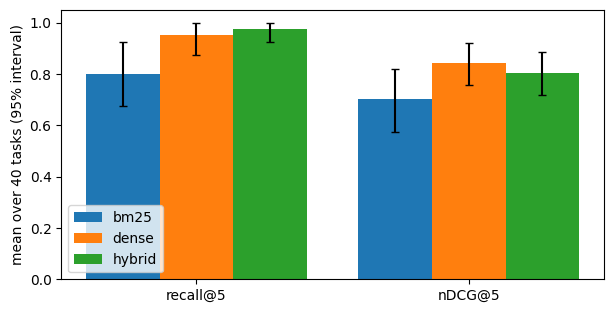

In [69]:
CATALOG = lab.tool_catalog()
TOOL_NAMES = [t["function"]["name"] for t in CATALOG]
TOOLS_DS = index("tools")
TASKS = [task for task, _ in lab.TOOL_TASKS]
embed_cached(TASKS)  # one batch instead of one per task

def find_tools(how, query, k=5):
    """The k best tools for query: bm25 alone, dense alone, or hybrid (lexical + dense, without reranking)."""
    if how == "bm25":
        return bm25_search(TOOLS_DS, query, k=k)
    if how == "dense":
        return np.argsort(-(VEC["tools"][0] @ embed_cached([query])[0]), kind="stable")[:k]
    return search(TOOLS_DS, query, k=k, rerank=False)

def rank_of(rows, i):
    return list(rows).index(i) + 1 if i in list(rows) else 99

RANKS = {how: np.array([rank_of(find_tools(how, task, 20), TOOL_NAMES.index(wanted)) for task, wanted in lab.TOOL_TASKS])
         for how in ("bm25", "dense", "hybrid")}
METRICS = {how: {"recall@5": (r <= 5).astype(float), "nDCG@5": np.where(r <= 5, 1 / np.log2(r + 1), 0.0)}
           for how, r in RANKS.items()}  # one relevant tool: its gain at rank r is 1 / log2(r + 1)
fig, ax = plt.subplots(figsize=(7, 3.5))
print(f"{'':8s}{'recall@5':>10s}{'nDCG@5':>8s}")
for k, (how, m) in enumerate(METRICS.items()):
    means = [x.mean() for x in m.values()]
    lo, hi = np.array([lab.bootstrap(x) for x in m.values()]).T
    ax.bar(np.arange(2) + 0.27 * (k - 1), means, 0.27, yerr=[np.array(means) - lo, hi - np.array(means)], capsize=3, label=how)
    print(f"{how:8s}{m['recall@5'].mean():10.2f}{m['nDCG@5'].mean():8.2f}")
ax.set_xticks(range(2), list(METRICS["bm25"]))
ax.set_ylabel(f"mean over {len(TASKS)} tasks (95% interval)")
ax.set_ylim(0, 1.05)
ax.legend();

In [70]:
print("hybrid's misses:")
for (task, wanted), r in zip(lab.TOOL_TASKS, RANKS["hybrid"]):
    if r > 5:
        print(f"  {task}\n    wanted {wanted} (rank {r}); top 3: {' · '.join(TOOL_NAMES[i] for i in find_tools('hybrid', task, 3))}")

hybrid's misses:


  Let Mikko know privately that the build is green.
    wanted send_direct_message (rank 15); top 3: rollback_deployment · pin_chat_message · restart_service


In [71]:
TOOL_SYSTEM = ("You are a workplace assistant with a catalog of about 60 tools. You start with search_tools only: describe what "
               "you need, and the tools it finds become callable on your next turn. Do the request with the right tool; do not "
               "ask questions, fill in reasonable values for missing details.")
SEARCH_TOOLS = tool("search_tools", "Find tools in the catalog by describing what you want to do. Returns the 5 best tools; "
                    "they become callable on your next turn.", ["query"], query=dict(type="string"))
SCHEMA = dict(zip(TOOL_NAMES, CATALOG))
BEST = max(METRICS, key=lambda how: METRICS[how]["nDCG@5"].mean())

def tool_agent(task, budget=4, verbose=False):
    """The model starts with search_tools (BEST's ranking); each turn's searches replace the tools offered before (the
    lab allows 8 per call). The catalog's tools do nothing and answer {"ok": true}."""
    messages = [dict(role="system", content=TOOL_SYSTEM), dict(role="user", content=task)]
    offered, called, searches, tokens = [], [], 0, 0
    for turn in range(budget):
        reply = chat(messages, [SEARCH_TOOLS, *offered])
        tokens += reply["usage"]["total_tokens"]
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        found = []
        for call in msg.get("tool_calls") or []:
            name, args = call["function"]["name"], json.loads(call["function"]["arguments"])
            if name == "search_tools":
                searches += 1
                found += [TOOL_NAMES[i] for i in find_tools(BEST, args["query"])]
                out = json.dumps([SCHEMA[n]["function"] for n in found[-5:]])
            else:
                called.append(name)
                out = json.dumps(dict(ok=True))
            if verbose:
                print(f"{name}  {json.dumps(args)}" + (f"\n  → {' · '.join(found[-5:])}" if name == "search_tools" else ""))
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if found:
            offered = [SCHEMA[n] for n in list(dict.fromkeys(found))[:7]]
        if not msg.get("tool_calls"):
            break
    return dict(called=called, searches=searches, tokens=tokens)

print(lab.TOOL_TASKS[3][0])
r = tool_agent(lab.TOOL_TASKS[3][0], verbose=True)
print(f"\nCalled: {' · '.join(r['called']) or 'nothing'} · {r['searches']} searches · {r['tokens']:,} tokens")

When could Anna, Jonas and I all meet for an hour next week?


search_tools  {"query": "find common availability for calendar schedules"}
  → schedule_meeting_room · list_calendar_events · find_free_slot · create_calendar_event · cancel_calendar_event


find_free_slot  {"attendees": "Anna, Jonas", "duration_minutes": "60"}


search_tools  {"query": "suggest meeting time options for attendees"}
  → find_free_slot · schedule_meeting_room · send_meeting_invite · create_calendar_event · crm_log_call



Called: find_free_slot · 2 searches · 6,050 tokens


In [72]:
DEMO = lab.TOOL_TASKS[::4]
with ThreadPoolExecutor(8) as pool:
    TOOL_RUNS = list(pool.map(lambda task: tool_agent(task[0]), DEMO))
for (task, wanted), r in zip(DEMO, TOOL_RUNS):
    print(f"{'✓' if r['called'][:1] == [wanted] else '✗'} {task}\n    wanted {wanted}; called {' · '.join(r['called']) or 'nothing'}")
print(f"\nfirst call the right tool: {np.mean([r['called'][:1] == [t] for (_, t), r in zip(DEMO, TOOL_RUNS)]):.0%}; "
      f"searches per task {np.mean([r['searches'] for r in TOOL_RUNS]):.1f}; tokens per task {np.mean([r['tokens'] for r in TOOL_RUNS]):,.0f}")

✓ Book the Fjord room tomorrow from 14 to 15 for our design review.
    wanted schedule_meeting_room; called schedule_meeting_room
✗ Write back to Tom's last email and tell him Thursday works.
    wanted reply_to_email; called search_email · search_email
✓ Let Mikko know privately that the build is green.
    wanted send_direct_message; called send_direct_message
✓ Mark ticket 4812 as solved.
    wanted update_ticket_status; called update_ticket_status
✗ I need the onboarding guide as a PDF to send to a contractor.
    wanted export_document_pdf; called nothing
✓ Elias starts with us on 3 November; get his paperwork and laptop going.
    wanted start_onboarding; called start_onboarding
✓ Here's my taxi receipt from the client visit, 38 euros.
    wanted submit_expense_report; called submit_expense_report
✓ Ship version 2.14 of the billing service to production.
    wanted deploy_service; called deploy_service
✓ The whole site is down, open a sev-1.
    wanted create_incident; called cr

Let's implement tool search in our agent. The agent works in the CRM of section 23 and its tools act for real: each task gets a fresh copy of the 600 deals, plus what the actions write (notes on deals, follow-up tasks, sent emails, calendar events), and every contact person sits in the CRM with an email address. The catalog holds 67 tools: the 60 workplace tools above, section 23's search tools, and four more CRM actions. Of the workplace tools, the CRM, email and calendar ones act on this world; the rest do nothing and answer `{"ok": true}`. Each of the 13 tasks needs both retrieval and action, e.g. "every open fintech deal in the Nordics: add a follow-up task for next Monday" means finding the deals with the attribute search and then writing one task on each.

A task is *completed* when the end state equals the state that the task's scripted solution leaves behind: the right deals changed in the right way, no other deal touched, and the notes and emails mention what the task asks. The world, its tools and the tasks live in `crm_world.py`.

In [68]:
import crm_world

print(f"{len(crm_world.CATALOG)} tools: the {len(CATALOG)} of the workplace catalog and "
      + ", ".join(t["function"]["name"] for t in crm_world.CRM_TOOLS))
c = crm_world.CONTACT_OF["D0387"]
print(f"\nThe contact at D0387 {c['company']}: {c['name']}, {c['role']}, {c['email']}")
print(f"\n{len(crm_world.TASKS)} tasks and the deals each changes:\n")
for t in crm_world.TASKS:
    print(f"  {len({key for _, key in crm_world._WANT[t.text]}):2d}  {t.text}")

67 tools: the 60 of the workplace catalog and search_deals, find_values, find_fields, crm_get_deal, crm_set_deal_owner, crm_add_deal_note, crm_create_follow_up_task

The contact at D0387 Zenith Group: Marco Garcia, COO, marco.garcia@zenithgroup.example

13 tasks and the deals each changes:

   1  Move Zenith Group's deal to negotiation.
   1  Log a note on deal D0250 that legal approved the terms.
   4  Every open fintech deal in the Nordics: add a follow-up task for next Monday.
   1  Email the contact at the biggest German deal in proposal stage and say we can meet Thursday.
   3  Hand Mikko's open deals in Austria over to Sara Lindqvist.
   1  We lost the Fjord Systems deal to Vantage: close it as lost and note why.
   1  Book a 30-minute call with our contact at Aurora Labs on Thursday at 10.
   3  Maria's three open deals that have gone quiet the longest: add a follow-up task for tomorrow to each.
   2  Open deals in Germany where our champion left: note on each that we need a new

In [69]:
CRM_TOOL_SYSTEM = (f"You work in our CRM for the sales team. Today is {crm_world.TODAY}. A deal is open until it is won "
                   "or lost. Do the request with the tools; do not ask questions. When it is done, say so in one sentence. You start "
                   "with search_tools only: describe what you need, and the tools it finds become callable on your next turn.")
ids, titles, bodies = crm_world.tool_documents()
d = embed_cached([f"{t}\n{x}" for t, x in zip(titles, bodies)])
VEC["crm-tools"], DOC_BITS["crm-tools"] = (d, None), (d.mean(0), signs(d - d.mean(0)))
CRM_TOOLS_DS = lab.Dataset("crm-tools", ids, titles, bodies, {}, {}, {})

def find_crm_tools(how, query, k=5):
    """find_tools on the CRM catalog."""
    if how == "bm25":
        return bm25_search(CRM_TOOLS_DS, query, k=k)
    if how == "dense":
        return np.argsort(-(VEC["crm-tools"][0] @ embed_cached([query])[0]), kind="stable")[:k]
    return search(CRM_TOOLS_DS, query, k=k, rerank=False)

def crm_tool_agent(task, how, budget=8):
    """tool_agent on a fresh CRM world, with real tool results and up to `budget` model calls: search_tools ranks the
    catalog with how, and the 7 tools found most recently are callable."""
    world = crm_world.World()
    messages = [dict(role="system", content=CRM_TOOL_SYSTEM), dict(role="user", content=task.text)]
    offered, log, tokens, cost = [], [], 0, 0.0
    for turn in range(budget):
        reply = chat(messages, [SEARCH_TOOLS, *offered])
        tokens, cost = tokens + reply["usage"]["total_tokens"], cost + reply["usage"].get("cost", 0.0)
        msg = reply["choices"][0]["message"]
        messages.append(msg)
        found = []
        for call in msg.get("tool_calls") or []:
            name = call["function"]["name"]
            try:
                args = json.loads(call["function"]["arguments"] or "{}")
            except ValueError:
                args = {}
            args = args if isinstance(args, dict) else {}
            if name == "search_tools":
                found += [ids[i] for i in find_crm_tools(how, str(args.get("query", "")))]
                out = json.dumps([crm_world.TOOLS[n]["function"] for n in found[-5:]])
            elif name not in [t["function"]["name"] for t in offered]:
                out = json.dumps(dict(error=f"{name} is not callable now; find it with search_tools"))
            else:
                out = world.call(name, args)
            log.append((name, args, found[-5:] if name == "search_tools" else out))
            messages.append(dict(role="tool", tool_call_id=call["id"], content=out))
        if found:
            names = list(dict.fromkeys(found[::-1] + [t["function"]["name"] for t in offered]))[:7]
            offered = [crm_world.TOOLS[n] for n in names]
        if not msg.get("tool_calls"):
            break
    return dict(task=task, status=crm_world.grade(task, world), world=world, log=log, tokens=tokens, cost=cost,
                calls=sum(name != "search_tools" for name, _, _ in log), searches=sum(name == "search_tools" for name, _, _ in log))

We run every task three times, with tool search ranking the catalog by BM25, by dense retrieval (the best ranking above) and by the hybrid of the two (lexical + dense, as `find_tools("hybrid", …)` ranks). Putting all tools in context is no option: with hundreds of tools the schemas alone would fill the context. A failed task has one of three causes, the lesson of section 23 in action form: *wrong deals* (a deal outside the task was changed), *incomplete* (a deal the task needs was missed or changed wrongly), and *nothing changed* (the agent found no tool that acts, or only called tools that do nothing here). Look at how many tasks each ranking completes, at what it spends, and at which kind of failure each makes.

In [70]:
ARMS = {"tool search, bm25": "bm25", "tool search, dense": "dense", "tool search, hybrid": "hybrid"}
with ThreadPoolExecutor(8) as pool:
    CRM_TOOL_RUNS = {arm: list(pool.map(lambda t, how=how: crm_tool_agent(t, how), crm_world.TASKS)) for arm, how in ARMS.items()}
STATUSES = ("completed", "wrong deals", "incomplete", "nothing changed")
print(f"{'':24s}" + "".join(f"{s:>16s}" for s in STATUSES)
      + f"{'tool calls':>12s}{'searches':>10s}{'tokens':>9s}{'cost':>8s}")
for arm, rs in CRM_TOOL_RUNS.items():
    n = Counter(r["status"] for r in rs)
    print(f"{arm:24s}" + "".join(f"{n[s]:16d}" for s in STATUSES) + f"{np.mean([r['calls'] for r in rs]):12.1f}"
          f"{np.mean([r['searches'] for r in rs]):10.1f}{np.mean([r['tokens'] for r in rs]):9,.0f}{sum(r['cost'] for r in rs):8.3f}")
print(f"\nOf {len(crm_world.TASKS)} tasks, completed: " + " | ".join(ARMS))
for t, *rs in zip(crm_world.TASKS, *CRM_TOOL_RUNS.values()):
    print("  ".join("✓" if r["status"] == "completed" else "✗" for r in rs), t.text)

                               completed     wrong deals      incomplete nothing changed  tool calls  searches   tokens    cost
tool search, bm25                      5               0               3               5         6.2       3.6   24,671   0.046
tool search, dense                    11               0               1               1         5.2       2.5   20,244   0.038
tool search, hybrid                   10               0               2               1         5.6       2.5   25,766   0.048

Of 13 tasks, completed: tool search, bm25 | tool search, dense | tool search, hybrid
✓  ✓  ✓ Move Zenith Group's deal to negotiation.
✓  ✓  ✓ Log a note on deal D0250 that legal approved the terms.
✗  ✓  ✗ Every open fintech deal in the Nordics: add a follow-up task for next Monday.
✗  ✓  ✓ Email the contact at the biggest German deal in proposal stage and say we can meet Thursday.
✓  ✓  ✓ Hand Mikko's open deals in Austria over to Sara Lindqvist.
✗  ✓  ✓ We lost the Fjord Systems d

In [71]:
def plain(x, top=True):
    """Arguments as short text: keys and values, without quotes and brackets."""
    if isinstance(x, dict):
        return ("; " if top else ", ").join(f"{k} {plain(v, False)}" for k, v in x.items())
    return " · ".join(plain(v, False) for v in x) if isinstance(x, list) else str(x)

def said(out):
    """A tool's answer in one line."""
    if isinstance(out, list):  # the tools that search_tools found
        return " · ".join(out)
    out = json.loads(out)
    if isinstance(out, dict) and "contacts" in out:
        return f"{out['total']} contacts: " + " · ".join(f"{c['name']} {c['email']}" for c in out["contacts"][:3])
    if isinstance(out, list) or "deals" in out or "error" in out:
        return brief(out)
    return plain({k: v for k, v in out.items() if k != "ok"}) or "ok"

r = min((r for r in CRM_TOOL_RUNS[f"tool search, {BEST}"] if len(r["task"].solution) > 2), key=lambda r: r["status"] != "completed")
print(r["task"].text + "\n")
for name, args, out in r["log"]:
    print(f"  {name:27s}{lab.cut(plain(args or {}), 90)}\n  {'':27s}→ {lab.cut(said(out), 90)}")
print("\nEnd state:")
for (kind, key), values in sorted(crm_world.effects(r["world"]).items()):
    print(f"  {kind:7s}{key:7s}" + " · ".join(lab.cut(v, 60) for v in values))
print(f"\n{r['status']} · {r['calls']} tool calls · {r['searches']} searches · {r['tokens']:,} tokens")

Every open fintech deal in the Nordics: add a follow-up task for next Monday.

  search_tools               query search deals in CRM list open deals
                             → search_deals · crm_get_deal · crm_create_deal · crm_search_contacts · crm_add_deal_note
  search_tools               query add follow-up task to a deal
                             → crm_create_follow_up_task · crm_get_deal · crm_add_deal_note · crm_create_deal · crm_upda…
  search_deals               filters industry fintech, country Sweden · Norway · Denmark · Finland · Iceland; fields d…
                             → 0 deals:
  search_deals               fields deal_id · company · stage · country · industry; limit 50
                             → 600 deals: D0001 Elm Motors, D0002 Lumen Logistics, D0003 Sable Partners, D0004 Harbor Fo…
  search_deals               filters industry fintech; fields deal_id · company · stage · country · industry; limit 50
                             → 0 deals:
  search_de

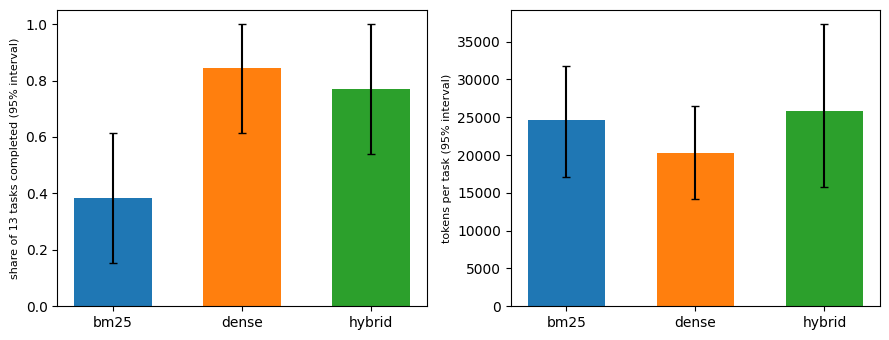

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for k, (arm, how) in enumerate(ARMS.items()):
    completed = np.array([r["status"] == "completed" for r in CRM_TOOL_RUNS[arm]], dtype=float)
    tokens = np.array([r["tokens"] for r in CRM_TOOL_RUNS[arm]], dtype=float)
    for ax, x in zip(axes, (completed, tokens)):
        lo, hi = lab.bootstrap(x)
        ax.bar(k, x.mean(), 0.6, yerr=[[x.mean() - lo], [hi - x.mean()]], capsize=3, color=f"C{k}", label=how)
for ax in axes:
    ax.set_xticks(range(len(ARMS)), list(ARMS.values()))
axes[0].set_ylabel(f"share of {len(crm_world.TASKS)} tasks completed (95% interval)", fontsize=8)
axes[0].set_ylim(0, 1.05)
axes[1].set_ylabel("tokens per task (95% interval)", fontsize=8)
fig.tight_layout();

Tool search with the dense ranking completed 11 of the 13 tasks, hybrid 10 and BM25 5. Hybrid is not the best here: dense completed one task more and spent the fewest tokens, about 20,000 per task against about 25,000 for the other two. In the plot, the intervals of dense and hybrid overlap widely, while BM25's lies mostly below both. No ranking touched a wrong deal. BM25 failed by changing nothing (5 tasks) or by leaving a task incomplete (3); dense's 2 failures and hybrid's 3 are of the same two kinds. Dense also has the highest nDCG@5 above, so the ranking that put the wanted tool highest there served the agent best too. Thirteen tasks are few, though: in an earlier run hybrid completed 10 and dense 8, so the gap between dense and hybrid is within the noise, while BM25 completed the fewest in every run.